# AI Technologies (Basic Course) · Notebook 02
## Topic 1. Fundamentals of computer vision in Google Colab for UAV and UGV tasks

| Lesson | Type, duration | Title |
|---|---|---|
| **1.3** | Practical class, 2 h | Setting up Google Colab and first work with frames of electro-optical systems |
| **1.4** | Practical class, 2 h | Processing of video streams of UAVs and ground robotic platforms |

Course: *AI Technologies (Basic Course)*, AIT-BC · Content module 1 · Kruty Heroes Military Institute of Telecommunications and Information Technology, Kyiv, 2026.

**How to work with this notebook**

1. Run the cells from top to bottom: *Runtime → Run all*, or `Shift+Enter` cell by cell. After a restart of the runtime run the cells again from task 1.3.2.
2. Every task begins with a text cell: the purpose of the task, the parameters of the form, the expected result and the control question. Answers to the control questions are written in the text cell **Report** at the end of each lesson.
3. Parameters are set in the forms of the code cells. Cells marked **[auto]** run again after every change of a parameter.
4. Code cells marked **(code shown)** are part of the practical skills of the lesson: read them, change them and run them again.
5. The results of the lessons are saved in the course project on Google Drive (`data`, `frames`, `models`, `outputs`); Notebook 01 created the structure, task 1.3.5 checks it and creates it again if it is missing.

**Data.** Real open data sets with manual annotation (see "Data sources and licences" at the end):
- **HIT-UAV** — thermal images and 5 thermal videos of a DJI Matrice M210 V2 UAV (60–130 m, day and night);
- **Kust4K** — pixel-aligned visible and thermal image pairs of a UAV over city roads;
- **VisDrone** — visible images of camera drones over cities;
- **M3OT** — synchronised visible and thermal image sequences of two DJI Mavic 3T drones (100–120 m, 10 frames per second, day, dusk and night) with vehicle tracks;
- **GOOSE** — image sequences of the front camera of a ground vehicle in fields and forests.

**Contents**

- **Lesson 1.3 (practical)** — 1.3.1 own notebook and GPU · 1.3.2 Python and the computer vision libraries · 1.3.3 visible frame of a UAV · 1.3.4 thermal frame and comparison with the visible one · 1.3.5 project structure on Google Drive · report
- **Lesson 1.4 (practical)** — 1.4.1 Google Drive and a UAV video fragment · 1.4.2 decomposition of a video into frames with a given sampling rate · 1.4.3 grid of frames for visual analysis · 1.4.4 thermal video fragment by the same method · 1.4.5 saving of the frame sets · 1.4.6 additional task: video of a ground robotic platform · report
- **Final self-check**, data sources and licences, next notebook

---
# Lesson 1.3 (Practical class). Setting up Google Colab and first work with frames of electro-optical systems

**Learning questions**
1. Creation of an own notebook in the Google Colab environment and activation of the GPU mode.
2. Checking the version of Python and installation of the basic stack of computer vision libraries.
3. Loading a test frame from the electro-optical system of a UAV and its display in the notebook.
4. Loading a test thermal frame and its comparison with the image in the visible spectrum.
5. Forming the structure of the project in Google Drive: data, frames, models, outputs.

**Result of the lesson.** A working notebook with the GPU runtime, a table of the versions of the libraries, a visible and a thermal frame of a UAV with their properties, and the project structure on Google Drive with the first saved frames.

## Task 1.3.1. Own notebook in Google Colab and the GPU mode

**Steps.**
1. Open https://colab.research.google.com and sign in with a Google account.
2. *File → New notebook in Drive*: the notebook is created in the folder *My Drive / Colab Notebooks*. Rename it: *File → Rename*, for example `AITBC_<surname>_lesson_1_3.ipynb`. This notebook (Notebook 02) is opened by *File → Upload notebook* or from Google Drive.
3. *Runtime → Change runtime type → Hardware accelerator: T4 GPU → Save*. The runtime restarts.
4. Run the cell below. It reports whether the notebook runs in Colab and whether a GPU is available, and measures the speed of a matrix multiplication on the CPU and on the GPU.

**Parameters.** `MATRIX_SIZE` — size $n$ of the square matrices of the test; `REPEATS` — number of repetitions.

**Expected result.** In the GPU runtime the table shows the name of the GPU (for example *Tesla T4*) and a speed of several TFLOP/s against tens or hundreds of GFLOP/s of the CPU. A matrix product of size $n$ takes $2n^3$ floating-point operations, therefore the speed is

$$P = \frac{2 n^3}{t}, \tag{1}$$

FLOP/s, where $t$ is the time of one multiplication, s.

**Control question 1.** Why is the first run of an operation on the GPU slower than the following runs, and why does the code call `torch.cuda.synchronize()` before stopping the timer?

In [1]:
#@title 1.3.1 Runtime and GPU check { display-mode: "form" }
MATRIX_SIZE = 2048 #@param {type:"slider", min:256, max:8192, step:256}
REPEATS = 5 #@param {type:"slider", min:1, max:20, step:1}

import sys, os, platform, time, json, math, shutil, subprocess, importlib
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
WORK_DIR = "/content" if IN_COLAB else os.getcwd()
try:
    import torch
    CUDA_OK = torch.cuda.is_available()
except ImportError:
    torch, CUDA_OK = None, False

rows = [("Environment", "Google Colab" if IN_COLAB else "local Jupyter")]
try:
    out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
                         capture_output=True, text=True, timeout=15).stdout.strip()
except (FileNotFoundError, subprocess.TimeoutExpired):
    out = ""
rows.append(("GPU (nvidia-smi)", out or "not available: Runtime → Change runtime type → T4 GPU"))


def matmul_speed(device):
    a = torch.randn(MATRIX_SIZE, MATRIX_SIZE, device=device)
    b = torch.randn(MATRIX_SIZE, MATRIX_SIZE, device=device)
    (a @ b).sum().item()                                   # warm-up: memory allocation, kernel selection
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(REPEATS):
        c = a @ b
    if device == "cuda":
        torch.cuda.synchronize()                           # wait until the GPU has finished
    t = (time.perf_counter() - t0) / REPEATS
    return t, 2 * MATRIX_SIZE ** 3 / t                     # formula (1)


if torch is not None:
    t_cpu, p_cpu = matmul_speed("cpu")
    rows.append((f"CPU: {MATRIX_SIZE} x {MATRIX_SIZE} matrix product", f"{t_cpu * 1000:.1f} ms, {p_cpu / 1e9:.1f} GFLOP/s"))
    if CUDA_OK:
        t_gpu, p_gpu = matmul_speed("cuda")
        rows.append((f"GPU: {MATRIX_SIZE} x {MATRIX_SIZE} matrix product", f"{t_gpu * 1000:.2f} ms, {p_gpu / 1e12:.2f} TFLOP/s"))
        rows.append(("Acceleration t_CPU / t_GPU", f"{t_cpu / t_gpu:.0f}"))
display(pd.DataFrame(rows, columns=["Item", "Value"]).set_index("Item"))

,Value
Item,
Environment,local Jupyter
GPU (nvidia-smi),"NVIDIA GeForce RTX 3060 Laptop GPU, 6144 MiB, ..."
CPU: 2048 x 2048 matrix product,"48.0 ms, 357.7 GFLOP/s"


## Task 1.3.2. Python version and the basic stack of computer vision libraries

**Purpose.** To check the versions of Python and of the libraries, to install the missing ones and to install the course library `aitbc` with access to the data sets.

The libraries of the stack and their role:
- **NumPy** — arrays; an image is an array H × W × C;
- **OpenCV** (`cv2`) — reading and writing images and video, colour conversion, filters, geometry;
- **Matplotlib** — display of images and plots;
- **pandas** — tables (annotations, results);
- **PyTorch** — tensors on CPU and GPU, neural networks (Topics 4–5);
- **Ultralytics** — YOLO detectors (Topic 5); installed in Colab by `pip install ultralytics`.

**Parameters.**
- `INSTALL_ULTRALYTICS` — install Ultralytics now (about 1 min); it is needed only from Topic 5.
- `CACHE_ON_DRIVE` — keep the downloaded data in Google Drive (folder `MyDrive/AITBC/data_cache`): the next session does not download them again.

**Expected result.** A table with the versions and the status `OK` for every required library; the message of the course library about the connected data sets.

**Control question 2.** Why is the table of versions saved together with the results of every experiment (file `project.json`, task 1.3.5)?

In [2]:
#@title 1.3.2 Python, library versions and the course library { display-mode: "form" }
INSTALL_ULTRALYTICS = False #@param {type:"boolean"}
CACHE_ON_DRIVE = False #@param {type:"boolean"}

REQUIRED = {"numpy": "1.24", "cv2": "4.8", "matplotlib": "3.7", "pandas": "2.0", "torch": "2.0"}


def version_tuple(v):
    return tuple(int("".join(ch for ch in x if ch.isdigit()) or 0) for x in v.split(".")[:2])


if INSTALL_ULTRALYTICS:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ultralytics"], check=False)
rows = [("Python", platform.python_version(), "3.10", "OK" if sys.version_info >= (3, 10) else "update")]
for mod, need in list(REQUIRED.items()) + [("ultralytics", "8.0")]:
    try:
        m = importlib.import_module(mod)
        v = getattr(m, "__version__", "?")
        status = "OK" if version_tuple(v) >= version_tuple(need) else "update"
    except ImportError:
        v, status = "not installed", "install" if mod != "ultralytics" else "optional (Topic 5)"
    rows.append(({"cv2": "opencv (cv2)"}.get(mod, mod), v, need, status))
VERSIONS = pd.DataFrame(rows, columns=["Library", "Installed", "Required at least", "Status"]).set_index("Library")
display(VERSIONS)

LIB_SOURCE = r'''"""
aitbc - course library of "AI Technologies (Basic Course)" (AIT-BC).

Kruty Heroes Military Institute of Telecommunications and Information Technology,
Kyiv, 2026.

All demonstrations of the course use REAL open data sets recorded by UAVs and
ground vehicles. Only the files that a block needs are downloaded: large archives
are read selectively with HTTP range requests, and every file is cached in
DATA_ROOT (a Google Drive folder keeps the cache between sessions).

Data sets
---------
HIT-UAV   2898 thermal (LWIR) images 640x512 and 5 thermal videos. DJI Matrice
          M210 V2 with a Zenmuse XT2 camera (25 mm lens, field of view 25 x 20 deg),
          flight altitude 60-130 m, camera angle 30-90 deg, day and night. Boxes of
          Person, Car, Bicycle, OtherVehicle, DontCare.
          Suo J. et al. Scientific Data 10, 227 (2023). Licence CC BY 4.0.
Kust4K    4024 pixel-aligned visible (RGB) and thermal (TIR) image pairs 640x512
          from a hexacopter over urban roads, day and night; pixel labels of 8 classes.
          Scientific Data 12, 1701 (2025). Licence CC BY 4.0.
VisDrone  RGB images of drones over cities (VisDrone2019-DET validation part,
          548 images) with boxes of pedestrians, vehicles and other objects.
          Zhu P. et al. IEEE TPAMI 44(11), 7380-7399 (2022).
GOOSE     camera images of a ground vehicle on roads, field tracks, in forests and on
          a training area, with pixel labels of 64 classes (validation part, 962 images).
          IEEE ICRA 2024. Licence CC BY-SA 4.0.
M3OT      synchronised visible and thermal image sequences of two DJI Mavic 3T drones
          (100-120 m, 10 fps, 640x512, day, dusk, night) with vehicle tracks.
          Nie Z. et al. Scientific Data 12, 1927 (2025). Licence CC BY 4.0.

Units: metres, seconds, degrees. Images are NumPy arrays H x W (grey) or H x W x 3 (RGB).
"""

__version__ = "2.1.0"

import csv
import io
import json
import math
import os
import struct
import time
import urllib.error
import urllib.request
import zlib
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import cv2

DATA_ROOT = os.environ.get("AITBC_DATA") or (
    "/content/aitbc_data" if os.path.isdir("/content") else os.path.abspath("aitbc_data"))


def set_data_root(path):
    """Set the folder of the download cache (for example a folder on Google Drive)."""
    global DATA_ROOT
    DATA_ROOT = os.path.abspath(path)
    os.makedirs(DATA_ROOT, exist_ok=True)
    return DATA_ROOT


def _cache(*parts):
    p = os.path.join(DATA_ROOT, *parts)
    os.makedirs(os.path.dirname(p), exist_ok=True)
    return p


def cache_size():
    """Number of files and size of the download cache, MB."""
    n, s = 0, 0
    for dp, _, fn in os.walk(DATA_ROOT):
        for f in fn:
            n += 1
            s += os.path.getsize(os.path.join(dp, f))
    return n, s / 1e6


# =============================================================================
# 1. Downloading
# =============================================================================
class _HTTPSRedirect(urllib.request.HTTPRedirectHandler):
    """Follow redirects, keep the Range header and upgrade http:// targets to https://."""

    def redirect_request(self, req, fp, code, msg, headers, newurl):
        if newurl.startswith("http://"):
            newurl = "https://" + newurl[len("http://"):]
        new = super().redirect_request(req, fp, code, msg, headers, newurl)
        if new is not None and req.has_header("Range"):
            new.add_header("Range", req.get_header("Range"))
        return new


_OPENER = urllib.request.build_opener(_HTTPSRedirect)
_OPENER.addheaders = [("User-Agent", "aitbc-course/2.0")]


def _urlopen(url, headers=None, timeout=60, retries=4):
    """Open url with retries; a new Request object is built for every attempt."""
    err = None
    for k in range(retries):
        try:
            return _OPENER.open(urllib.request.Request(url, headers=dict(headers or {})), timeout=timeout)
        except urllib.error.HTTPError as e:
            if e.code in (400, 401, 403, 404, 416):
                raise
            err = e
        except Exception as e:                      # network error: retry after a pause
            err = e
        time.sleep(1.5 * (k + 1))
    raise err


def fetch(url, path, timeout=120):
    """Download url to path; nothing is done when the file is already in the cache."""
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    tmp = path + ".part"
    with _urlopen(url, timeout=timeout) as r, open(tmp, "wb") as fh:
        while True:
            b = r.read(1 << 20)
            if not b:
                break
            fh.write(b)
    os.replace(tmp, path)
    return path


def fetch_many(jobs, threads=8):
    """jobs: list of (url, path); parallel download, returns the list of paths."""
    with ThreadPoolExecutor(threads) as ex:
        return list(ex.map(lambda j: fetch(*j), jobs))


class _RangeFile(io.RawIOBase):
    """Seekable read-only file over HTTP range requests (reads the directory of a remote zip)."""

    def __init__(self, url, chunk=1 << 17, timeout=60):
        self.url, self.chunk, self.timeout = url, chunk, timeout
        r = _urlopen(url, {"Range": "bytes=0-0"}, timeout)
        cr = r.headers.get("Content-Range")
        r.read()
        if r.status != 206 or not cr:
            raise IOError(f"the server of {url} does not support range requests")
        self.size = int(cr.split("/")[-1])
        self.pos, self.buf_start, self.buf = 0, 0, b""

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self.pos

    def seek(self, off, whence=0):
        self.pos = off if whence == 0 else (self.pos + off if whence == 1 else self.size + off)
        return self.pos

    def read(self, n=-1):
        if n is None or n < 0:
            n = self.size - self.pos
        n = min(n, self.size - self.pos)
        if n <= 0:
            return b""
        if not (self.buf_start <= self.pos and self.pos + n <= self.buf_start + len(self.buf)):
            start = self.pos
            end = min(self.size, start + max(n, self.chunk)) - 1
            self.buf = _urlopen(self.url, {"Range": f"bytes={start}-{end}"}, self.timeout).read()
            self.buf_start = start
        off = self.pos - self.buf_start
        out = self.buf[off:off + n]
        self.pos += len(out)
        return out

    def readinto(self, b):
        d = self.read(len(b))
        b[:len(d)] = d
        return len(d)


class RemoteZip:
    """Selective reading of members of a large remote zip archive: only the central
    directory and the requested members are transferred; members are cached on disk."""

    def __init__(self, url, cache_name):
        import zipfile
        self.url, self.cache_name = url, cache_name
        idx_path = _cache("_index", cache_name + ".json")
        if os.path.exists(idx_path):
            with open(idx_path) as fh:
                self.index = json.load(fh)
        else:
            zf = zipfile.ZipFile(_RangeFile(url))
            self.index = {i.filename: (i.header_offset, i.compress_size, i.file_size, i.compress_type)
                          for i in zf.infolist() if not i.filename.endswith("/")}
            with open(idx_path, "w") as fh:
                json.dump(self.index, fh)

    def namelist(self):
        return list(self.index)

    def _fetch_member(self, name):
        path = _cache(self.cache_name, name)
        if os.path.exists(path):
            return path
        off, csize, usize, ctype = self.index[name]
        raw = _urlopen(self.url, {"Range": f"bytes={off}-{off + 30 + 1024 + csize}"}).read()
        if raw[:4] != b"PK\x03\x04":
            raise IOError(f"bad local header of {name}")
        n, m = struct.unpack("<HH", raw[26:30])
        data = raw[30 + n + m: 30 + n + m + csize]
        if ctype == 8:
            data = zlib.decompressobj(-15).decompress(data)
        elif ctype != 0:
            raise IOError(f"unsupported compression {ctype} in {name}")
        if len(data) != usize:
            raise IOError(f"incomplete member {name}")
        with open(path + ".part", "wb") as fh:
            fh.write(data)
        os.replace(path + ".part", path)
        return path

    def get(self, names, threads=8):
        """Download members (a name or a list of names); returns local path(s)."""
        single = isinstance(names, str)
        names = [names] if single else list(names)
        with ThreadPoolExecutor(threads) as ex:
            paths = list(ex.map(self._fetch_member, names))
        return paths[0] if single else paths


def _rgb(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise IOError(f"cannot read {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


# =============================================================================
# 2. Data sets
# =============================================================================
class HITUAV:
    """HIT-UAV: thermal images and videos of a DJI Matrice M210 V2 with a Zenmuse XT2.

    File name T_HHH_AA_W_NNNNN: T = 0 day / 1 night, HHH = flight altitude, m,
    AA = camera angle, deg (90 = vertical view), W = 0 sunny / 1 rainy.
    Images are 8-bit white-hot (warm = bright) after the automatic gain control
    of the camera: brightness is a relative, not a calibrated, temperature."""

    PALETTE = "white-hot"
    BASE = "https://raw.githubusercontent.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset/main/"
    CLASSES = ("Person", "Car", "Bicycle", "OtherVehicle", "DontCare")
    COLORS = {"Person": (0, 229, 255), "Car": (255, 235, 59), "Bicycle": (118, 255, 3),
              "OtherVehicle": (255, 152, 0), "DontCare": (190, 190, 190)}
    CAMERA = dict(model="DJI Zenmuse XT2, uncooled VOx microbolometer", width=640, height=512,
                  focal_mm=25.0, pixel_pitch_um=17.0, hfov_deg=25.0, vfov_deg=20.0, band_um="7.5-13.5")
    EXAMPLES = ('1_60_30_0_00047.jpg', '0_60_60_0_01734.jpg', '1_70_90_0_07776.jpg', '0_100_50_0_08162.jpg', '1_120_90_0_06161.jpg', '0_130_40_0_05603.jpg', '1_90_70_0_04990.jpg', '0_110_80_0_08518.jpg')
    VIDEOS = {"60m-30_1.mov": "60 m, camera angle 30 deg: people on a sports ground",
              "60m-40_3.mov": "60 m, 40 deg: cars on a parking lot",
              "70m-90_1.mov": "70 m, 90 deg (vertical view): people on a square",
              "120m-30_3.mov": "120 m, 30 deg: road along buildings",
              "130m-60_3.mov": "130 m, 60 deg: parking lot and roads"}

    def __init__(self, splits=("train", "val", "test")):
        import pandas as pd
        imgs, objs = [], []
        jobs = [(self.BASE + f"normal_json/annotations/{sp}.json", _cache("hituav", "annotations", sp + ".json"))
                for sp in splits]
        for sp, path in zip(splits, fetch_many(jobs, 3)):
            with open(path) as fh:
                d = json.load(fh)
            cat = {c["id"]: c["name"] for c in d["categories"]}
            id2f = {}
            for im in d["images"]:
                fn = im.get("filename") or im.get("file_name")
                id2f[im["id"]] = fn
                t, h, a, w = fn.split("_")[:4]
                imgs.append(dict(file=fn, split=sp, night=t == "1", altitude=int(h), angle=int(a), rainy=w == "1"))
            for an in d.get("annotation", d.get("annotations", [])):
                x, y, w, h = an["bbox"]
                objs.append(dict(ann_id=an["id"], file=id2f[an["image_id"]], cls=cat[an["category_id"]],
                                 x1=float(x), y1=float(y), x2=float(x + w), y2=float(y + h)))
        # oriented boxes [xc, yc, w, h, angle]: true width and length of rotated objects
        rjobs = [(self.BASE + f"rotate_json/annotations/{sp}.json", _cache("hituav", "annotations", "rot_" + sp + ".json"))
                 for sp in splits]
        rot = {}
        for path in fetch_many(rjobs, 3):
            with open(path) as fh:
                d = json.load(fh)
            for an in d.get("annotations", d.get("annotation", [])):
                b = an["bbox"]
                rot[an["id"]] = (min(b[2], b[3]), max(b[2], b[3]), b[4] if len(b) > 4 else 0.0)
        self.images = pd.DataFrame(imgs).sort_values("file").reset_index(drop=True)
        o = pd.DataFrame(objs)
        o["w"], o["h"] = o.x2 - o.x1, o.y2 - o.y1
        o["width_px"] = o.ann_id.map(lambda i: rot.get(i, (np.nan,) * 3)[0])     # oriented box: short side
        o["length_px"] = o.ann_id.map(lambda i: rot.get(i, (np.nan,) * 3)[1])    # oriented box: long side
        self.objects = o.merge(self.images[["file", "night", "altitude", "angle"]], on="file", how="left")
        self._split = dict(zip(self.images.file, self.images.split))
        self._groups = {f: g for f, g in self.objects.groupby("file")}
        counts = self.objects.pivot_table(index="file", columns="cls", values="x1", aggfunc="count", fill_value=0)
        self.images = self.images.merge(counts, left_on="file", right_index=True, how="left").fillna(0)

    def _url(self, f):
        return self.BASE + f"normal_json/{self._split[f]}/{f}"

    def path(self, file):
        return fetch(self._url(file), _cache("hituav", self._split[file], file))

    def prefetch(self, files, threads=8):
        return fetch_many([(self._url(f), _cache("hituav", self._split[f], f)) for f in files], threads)

    def load(self, file):
        """Thermal image (H x W uint8) and the list of annotated objects."""
        img = cv2.imread(self.path(file), cv2.IMREAD_GRAYSCALE)
        g = self._groups.get(file)
        objs = [] if g is None else [dict(cls=r.cls, box=[r.x1, r.y1, r.x2, r.y2]) for r in g.itertuples()]
        return img, objs

    def video(self, name):
        return fetch(self.BASE + "video_sample/" + name, _cache("hituav", "video", name))

    @staticmethod
    def video_geometry(name):
        """Flight altitude, m, and camera angle, deg, from a video name such as '60m-30_1.mov'."""
        alt, rest = name.split("m-")
        return int(alt), int(rest.split("_")[0])

    def gsd(self, altitude, angle=90):
        """Ground sampling distance at the image centre, m/px (formula of Lesson 1.1)."""
        rng = altitude / max(math.sin(math.radians(angle)), 1e-3)
        return 2 * rng * math.tan(math.radians(self.CAMERA["hfov_deg"]) / 2) / self.CAMERA["width"]


class Kust4K:
    """Kust4K: pixel-aligned RGB and thermal (TIR) pairs 640x512 of a hexacopter
    HET-3021C over urban roads, day (id ...D) and night (id ...N), with pixel labels.

    The thermal images are pseudo-colour (palette from purple = cold to yellow = warm);
    tir_gray is their luminance, a relative thermal brightness. The data set contains
    frames with SIMULATED failures (visible channel set to zero, thermal channel
    blurred) made by its authors; they are excluded from the curated lists below."""

    PALETTE = "pseudo-colour (purple = cold, yellow = warm)"
    URL = "https://ndownloader.figshare.com/files/{}"
    FILES = {"rgb": 55979147, "tir": 55979165, "seg": 55979159}
    CLASSES = ("unlabelled", "road", "building", "motorcycle", "car", "truck", "tree", "person", "traffic facilities")
    COLORS = np.array([(0, 0, 0), (150, 150, 150), (229, 57, 53), (255, 152, 0), (255, 235, 59),
                       (236, 64, 122), (46, 160, 67), (0, 229, 255), (30, 136, 229)], np.uint8)
    OBJECTS = (3, 4, 5, 7)
    CAMERA = dict(platform="hexacopter HET-3021C", tir_focal_mm=9.1, tir_pixel_um=12.0,
                  rgb="1920x1080, f = 8 mm, registered to the thermal image and resized to 640x512")
    DAY = ("00720D", "00719D", "00031D", "01944D", "00851D", "00580D", "00990D", "00355D", "02094D", "02293D")
    NIGHT = ("02566N", "02807N", "02921N", "03135N", "03685N", "03895N", "03780N", "04004N", "02867N", "02599N")

    def __init__(self):
        self._z = {}

    def _zip(self, key):
        if key not in self._z:
            self._z[key] = RemoteZip(self.URL.format(self.FILES[key]), "kust4k_" + key)
        return self._z[key]

    def prefetch(self, ids, threads=6):
        names = [i + ".png" for i in ids]
        with ThreadPoolExecutor(3) as ex:
            list(ex.map(lambda k: self._zip(k).get(names, threads), ("rgb", "tir", "seg")))

    def pair(self, fid):
        """dict(id, night, rgb, tir, tir_gray, labels) for a frame id such as '00720D'."""
        self.prefetch([fid])
        name = fid + ".png"
        rgb = _rgb(self._zip("rgb").get(name))
        tir = _rgb(self._zip("tir").get(name))
        lab = cv2.imread(self._zip("seg").get(name), cv2.IMREAD_UNCHANGED)
        return dict(id=fid, night=fid.endswith("N"), rgb=rgb, tir=tir,
                    tir_gray=cv2.cvtColor(tir, cv2.COLOR_RGB2GRAY), labels=lab)


class VisDrone:
    """VisDrone2019-DET validation part: RGB images of drones with object boxes.
    Annotation line: x, y, w, h, score, category, truncation, occlusion."""

    URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/VisDrone2019-DET-val.zip"
    CLASSES = ("ignored region", "pedestrian", "people", "bicycle", "car", "van", "truck", "tricycle",
               "awning-tricycle", "bus", "motor", "others")
    COLORS = {"pedestrian": (0, 229, 255), "people": (0, 176, 255), "bicycle": (118, 255, 3), "car": (255, 235, 59),
              "van": (255, 193, 7), "truck": (255, 152, 0), "tricycle": (186, 104, 200),
              "awning-tricycle": (156, 39, 176), "bus": (244, 67, 54), "motor": (236, 64, 122)}

    CURATED = ('0000213_03920_d_0000243', '0000291_03801_d_0000887', '0000117_00112_d_0000087', '0000001_08414_d_0000013', '0000155_00401_d_0000001', '0000193_01705_d_0000112', '0000295_02400_d_0000033', '0000289_04601_d_0000834', '0000215_00000_d_0000256', '0000327_04001_d_0000731')

    def __init__(self):
        self.z = RemoteZip(self.URL, "visdrone_val")

    def names(self):
        return sorted(n.split("/")[-1][:-4] for n in self.z.namelist() if n.endswith(".jpg"))

    def _members(self, name):
        return [f"VisDrone2019-DET-val/images/{name}.jpg", f"VisDrone2019-DET-val/annotations/{name}.txt"]

    def prefetch(self, names, threads=8):
        self.z.get([m for n in names for m in self._members(n)], threads)

    def load(self, name):
        """RGB image and the list of objects (ignored regions and 'others' are skipped)."""
        pi, pa = self.z.get(self._members(name))
        objs = []
        with open(pa) as fh:
            for line in fh:
                v = line.strip().strip(",").split(",")
                if len(v) < 8:
                    continue
                x, y, w, h, _, c, trunc, occ = (int(float(s)) for s in v[:8])
                if c in (0, 11):
                    continue
                objs.append(dict(cls=self.CLASSES[c], box=[x, y, x + w, y + h], truncation=trunc, occlusion=occ))
        return _rgb(pi), objs


class M3OT:
    """M3OT: synchronised visible (RGB) and thermal (IR) image sequences of two DJI Mavic 3T
    drones flying at 100-120 m (10 frames per second, 640 x 512 px), day, dusk and night, with
    multi-object tracking annotation of vehicles (MOT format: frame, id, x, y, w, h, flag, class,
    confidence). The track identifiers are the same in the RGB and IR sequences of one drone.
    The two channels were aligned by the authors with an affine transform; a residual spatial
    offset of several pixels and a time offset of up to several frames remain (Lesson 1.4).

    The IR frames are 8-bit grey images in the BLACK-HOT palette (warm = dark). The data
    descriptor does not state the palette; it is established from the scene: in all nine
    sequences of drone 1 the road surface is darker than vegetation by day, at dusk and at night,
    while asphalt is, as a rule, the warmer surface (Lesson 1.3, task 1.3.4). Vehicles are
    bright, i.e. cooler than the road. to_white_hot() gives the white-hot convention of HIT-UAV."""

    PALETTE = "black-hot"
    URL = "https://ndownloader.figshare.com/files/52023875"
    CAMERA = dict(platform="DJI Mavic 3T", altitude_m="100-120", fps=10, width=640, height=512,
                  rgb="telephoto camera, f = 29.85 mm (35 mm equivalent 162 mm), frames registered to IR",
                  ir="uncooled thermal camera 640 x 512, f = 9.1 mm (35 mm equivalent 40 mm)")
    SEQUENCES = {"1-01": "day, suburban road", "1-02": "night, city crossroads", "1-03": "day, city road",
                 "1-04": "day, suburban highway", "1-05": "day, crossroads", "1-06": "dusk, highway",
                 "1-07": "day, crossroads", "1-08": "dusk, crossroads", "1-09": "day, city street with parked cars"}

    def __init__(self):
        self.z = RemoteZip(self.URL, "m3ot")
        self._seq = {}
        for n in self.z.namelist():
            parts = n.split("/")        # M3OT/<drone>/<rgb|ir>/<split>/<sequence>/img1/<frame>.PNG
            if len(parts) == 7 and parts[5] == "img1":
                self._seq.setdefault((parts[4].rstrip("T"), parts[2]), []).append(n)
        for k in self._seq:
            self._seq[k].sort()

    def sequences(self):
        return sorted({k[0] for k in self._seq})

    def n_frames(self, seq, channel="rgb"):
        return len(self._seq[(seq, channel)])

    def frame_names(self, seq, channel="rgb", start=0, count=None, step=1):
        names = self._seq[(seq, channel)]
        end = len(names) if count is None else min(len(names), start + count * step)
        return names[start:end:step]

    def prefetch(self, seq, channel="rgb", start=0, count=None, step=1, threads=8):
        return self.z.get(self.frame_names(seq, channel, start, count, step), threads)

    def frames(self, seq, channel="rgb", start=0, count=None, step=1):
        """List of RGB images (H x W x 3) of a sequence; IR frames are grey images in 3 equal channels."""
        return [_rgb(p) for p in self.prefetch(seq, channel, start, count, step)]

    def tracks(self, seq, channel="rgb"):
        """Annotation table: frame (from 1), id, x, y, w, h, cx, cy."""
        import pandas as pd
        names = self._seq[(seq, channel)]
        gt = names[0].rsplit("/img1/", 1)[0] + "/gt/gt.txt"
        g = pd.read_csv(self.z.get(gt), header=None, names=["frame", "id", "x", "y", "w", "h", "flag", "cls", "conf"])
        g["cx"], g["cy"] = g.x + g.w / 2, g.y + g.h / 2
        return g[["frame", "id", "x", "y", "w", "h", "cx", "cy"]]

    def objects(self, table, frame):
        """Objects of one frame in the format of draw_boxes."""
        t = table[table.frame == frame]
        return [dict(cls="vehicle", id=int(r.id), box=[r.x, r.y, r.x + r.w, r.y + r.h]) for r in t.itertuples()]


class GOOSE:
    """GOOSE: front camera of a ground vehicle (2048x1000) with pixel labels of 64 classes."""

    URL = "https://goose-dataset.de/storage/goose_2d_val.zip"
    TRAVERSABLE = ("asphalt", "cobble", "gravel", "soil", "low_grass", "moss", "leaves", "snow",
                   "road_marking", "pedestrian_crossing", "sidewalk", "bikeway")
    CONDITIONAL = ("high_grass", "crops", "debris", "tree_root")
    IGNORE = ("undefined", "sky", "ego_vehicle", "outlier")
    CURATED = (
        'labels/val/2022-07-22_flight/2022-07-22_flight__0078_1658494246011438339_labelids.png',
        'labels/val/2022-07-22_flight/2022-07-22_flight__0158_1658494465090456964_labelids.png',
        'labels/val/2022-08-30_siegertsbrunn_feldwege/2022-08-30_siegertsbrunn_feldwege__0528_1661860582736903436_labelids.png',
        'labels/val/2022-08-30_siegertsbrunn_feldwege/2022-08-30_siegertsbrunn_feldwege__0551_1661860697315889089_labelids.png',
        'labels/val/2022-09-21_garching_uebungsplatz_2/2022-09-21_garching_uebungsplatz_2__0002_1663755194931038715_labelids.png',
        'labels/val/2022-09-21_garching_uebungsplatz_2/2022-09-21_garching_uebungsplatz_2__0038_1663755353192423465_labelids.png',
        'labels/val/2023-03-03_garching_2/2023-03-03_garching_2__0114_1677850404544550420_labelids.png',
        'labels/val/2023-03-03_garching_2/2023-03-03_garching_2__0156_1677850669766430912_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0007_1670420722571435228_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0057_1670421449778652057_labelids.png',
        'labels/val/2022-12-07_aying_hills/2022-12-07_aying_hills__0037_1670421230548919820_labelids.png',
        'labels/val/2023-05-15_neubiberg_rain/2023-05-15_neubiberg_rain__0650_1684157928693659670_labelids.png',
    )

    def __init__(self):
        self.z = RemoteZip(self.URL, "goose_val")
        self.names, self.colors = {}, {}
        with open(self.z.get("goose_label_mapping.csv"), newline="") as fh:
            for row in csv.DictReader(fh):
                k = int(row["label_key"])
                h = row["hex"].lstrip("#")
                self.names[k] = row["class_name"]
                self.colors[k] = tuple(int(h[i:i + 2], 16) for i in (0, 2, 4))
        self.lut = np.zeros((256, 3), np.uint8)
        for k, c in self.colors.items():
            self.lut[k] = c
        self.id_of = {v: k for k, v in self.names.items()}

    def frames(self):
        return sorted(n for n in self.z.namelist() if n.endswith("_labelids.png"))

    @staticmethod
    def _image_member(label_member):
        return label_member.replace("labels/", "images/").replace("_labelids.png", "_windshield_vis.png")

    def prefetch(self, members, threads=6):
        self.z.get([m for lm in members for m in (self._image_member(lm), lm)], threads)

    def load(self, label_member, scale=0.5):
        """RGB image and label map (both resized by `scale`)."""
        pi, pl = self.z.get([self._image_member(label_member), label_member])
        img, lab = _rgb(pi), cv2.imread(pl, cv2.IMREAD_UNCHANGED)
        if scale != 1:
            w, h = int(img.shape[1] * scale), int(img.shape[0] * scale)
            img = cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)
            lab = cv2.resize(lab, (w, h), interpolation=cv2.INTER_NEAREST)
        return img, lab

    def traversability(self, lab):
        """0 = ignored (sky, own vehicle), 1 = traversable, 2 = conditionally traversable, 3 = obstacle."""
        lut = np.full(256, 3, np.uint8)
        for group, v in ((self.TRAVERSABLE, 1), (self.CONDITIONAL, 2), (self.IGNORE, 0)):
            for n in group:
                if n in self.id_of:
                    lut[self.id_of[n]] = v
        return lut[lab]


# =============================================================================
# 3. Camera geometry
# =============================================================================
def gsd_nadir(altitude, hfov_deg, width_px):
    """Ground sampling distance of a vertical view, m/px: GSD = 2 H tan(alpha/2) / N."""
    return 2 * altitude * math.tan(math.radians(hfov_deg) / 2) / width_px


def hfov_from_sensor(focal_mm, pixel_um, width_px):
    """Horizontal field of view, deg, from the focal length and the pixel pitch."""
    return math.degrees(2 * math.atan(width_px * pixel_um * 1e-3 / 2 / focal_mm))


# =============================================================================
# 4. Degradations of the video signal (applied to real frames)
# =============================================================================
def fractal_noise(shape, rng, octaves=5, start=3, persistence=0.5):
    """Smooth random field in [0, 1] (sum of up-sampled random grids)."""
    h, w = shape
    out = np.zeros((h, w), np.float32)
    amp, m = 1.0, max(h, w)
    for o in range(octaves):
        n = start * (2 ** o)
        grid = rng.random((max(2, int(round(n * h / m)) + 1), max(2, int(round(n * w / m)) + 1)), dtype=np.float32)
        out += amp * cv2.resize(grid, (w, h), interpolation=cv2.INTER_CUBIC)
        amp *= persistence
    out -= out.min()
    return out / max(float(out.max()), 1e-6)


def _f(img):
    return img.astype(np.float32)


def _u8(x):
    return np.clip(x, 0, 255).astype(np.uint8)


def motion_blur(img, length=9.0, angle=0.0):
    """Linear motion blur: the point spread function is a line of `length` px at `angle` deg."""
    if length < 1.5:
        return img.copy()
    size = int(math.ceil(length)) | 1
    k = np.zeros((size * 4, size * 4), np.uint8)
    c = size * 2
    dx = math.cos(math.radians(angle)) * (length - 1) * 2
    dy = -math.sin(math.radians(angle)) * (length - 1) * 2
    cv2.line(k, (int(c - dx), int(c - dy)), (int(c + dx), int(c + dy)), 255, 4, cv2.LINE_AA)
    k = cv2.resize(k.astype(np.float32), (size, size), interpolation=cv2.INTER_AREA)
    return cv2.filter2D(img, -1, k / max(k.sum(), 1e-6), borderType=cv2.BORDER_REFLECT)


def defocus(img, sigma=1.5):
    return img.copy() if sigma <= 0 else cv2.GaussianBlur(img, (0, 0), sigma)


def add_noise(img, sigma=10.0, seed=None):
    rng = np.random.default_rng(seed)
    return _u8(_f(img) + rng.normal(0, sigma, img.shape))


def low_light(img, level=0.15, gain_max=8.0, seed=None):
    """Dark scene and automatic gain: light reduced by `level`, photon and read noise added."""
    if level >= 0.999:
        return img.copy()
    rng = np.random.default_rng(seed)
    lin = (_f(img) / 255.0) ** 2.2 * level
    full_well = 3000.0
    noisy = lin + rng.standard_normal(lin.shape).astype(np.float32) * np.sqrt(lin / full_well + (4.0 / full_well) ** 2)
    gain = float(np.clip(0.16 / max(float(lin.mean()), 1e-6), 1.0, gain_max))
    return _u8(np.clip(noisy * gain, 0, 1) ** (1 / 2.2) * 255)


def haze(img, density=0.4, airlight=200.0):
    """Uniform haze: I = J t + A (1 - t), transmission t = 1 - density."""
    t = 1.0 - float(np.clip(density, 0, 0.98))
    return _u8(_f(img) * t + airlight * (1 - t))


def smoke(img, density=0.5, seed=0, color=170.0, opacity=0.92):
    """Smoke: spatially variable veil."""
    if density <= 0:
        return img.copy()
    n = fractal_noise(img.shape[:2], np.random.default_rng(seed))
    m = np.clip((n - (1.0 - density)) * 3.0, 0, 1) * opacity
    if img.ndim == 3:
        m = m[..., None]
    return _u8(_f(img) * (1 - m) + color * m)


def jpeg(img, quality=30):
    """JPEG compression artefacts."""
    if quality >= 100:
        return img.copy()
    x = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    _, buf = cv2.imencode(".jpg", x, [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    y = cv2.imdecode(buf, cv2.IMREAD_UNCHANGED)
    return y if img.ndim == 2 else cv2.cvtColor(y, cv2.COLOR_BGR2RGB)


def downscale(img, factor=0.5):
    """Loss of resolution: down-sample by `factor`, then up-sample back."""
    if factor >= 0.999:
        return img.copy()
    h, w = img.shape[:2]
    small = cv2.resize(img, (max(1, int(w * factor)), max(1, int(h * factor))), interpolation=cv2.INTER_AREA)
    return cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)


def rolling_shutter(img, amplitude=6.0, cycles=1.5, phase=0.0):
    """Rolling-shutter distortion: every row is shifted by a sinusoid of the row number."""
    if amplitude <= 0:
        return img.copy()
    h, w = img.shape[:2]
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    shift = amplitude * np.sin(2 * np.pi * cycles * yy / h + phase)
    return cv2.remap(img, xx + shift, yy, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)


def analog_interference(img, strength=0.5, seed=None):
    """Analog FPV video link with a weak or jammed signal: colour loss, snow, line
    noise, horizontal tearing (loss of synchronisation) and a rolling brightness bar."""
    if strength <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    h = img.shape[0]
    x = _f(img)
    if x.ndim == 3:
        gray = x.mean(axis=2, keepdims=True)
        x = gray + (x - gray) * (1 - 0.85 * min(strength * 1.3, 1))
    x += rng.normal(0, 45 * strength, x.shape)
    for r in rng.integers(0, h, int(h * 0.06 * strength)):
        x[r] += rng.normal(70, 40) * strength
    if strength > 0.25:
        y0, band = rng.integers(0, h), int(h * 0.25 * strength)
        offs = np.cumsum(rng.normal(0, 3.0 * strength, band))
        for i in range(band):
            r = (y0 + i) % h
            x[r] = np.roll(x[r], int(offs[i] + 30 * strength), axis=0)
    bar = 1.0 + 0.3 * strength * np.sin(2 * np.pi * (np.arange(h, dtype=np.float32)[:, None] / h * 1.3 + rng.random()))
    return _u8(x * (bar if x.ndim == 2 else bar[..., None]))


def packet_loss(img, rate=0.05, block=16, seed=None):
    """Digital link with lost packets: damaged macroblock slices are filled with a smear
    of the row above or with a grey block."""
    if rate <= 0:
        return img.copy()
    rng = np.random.default_rng(seed)
    out = img.copy()
    gh, gw = img.shape[0] // block, img.shape[1] // block
    lost = rng.random((gh, gw)) < rate
    for r in range(gh):
        c = 0
        while c < gw:
            if lost[r, c]:
                run = int(rng.integers(1, max(2, gw // 3)))
                lost[r, c:c + run] = True
                c += run
            c += 1
    for r, c in zip(*np.nonzero(lost)):
        ys, xs = slice(r * block, (r + 1) * block), slice(c * block, (c + 1) * block)
        if r > 0 and rng.random() < 0.6:
            out[ys, xs] = out[r * block - 1:r * block, xs]
        else:
            out[ys, xs] = 128 if img.ndim == 2 else (60, 128, 60)
    return out


def degrade(img, sensor="visible", motion_px=0.0, motion_angle=0.0, defocus_sigma=0.0, light=1.0, noise=0.0,
            haze_density=0.0, smoke_density=0.0, rolling=0.0, scale=1.0, jpeg_quality=100, analog=0.0,
            packet=0.0, seed=0):
    """Chain of degradations in physical order: atmosphere -> optics and motion -> sensor ->
    resolution -> compression -> radio link. For the thermal sensor haze and smoke are
    attenuated (long-wave infrared passes thin smoke and haze) and low light does not apply."""
    x, ir = img, sensor == "thermal"
    if haze_density > 0:
        x = haze(x, haze_density * (0.25 if ir else 1.0), airlight=128 if ir else 200)
    if smoke_density > 0:
        x = smoke(x, smoke_density, seed=seed, color=128 if ir else 170, opacity=0.18 if ir else 0.92)
    if motion_px > 0:
        x = motion_blur(x, motion_px, motion_angle)
    if defocus_sigma > 0:
        x = defocus(x, defocus_sigma)
    if rolling > 0:
        x = rolling_shutter(x, rolling)
    if light < 1.0 and not ir:
        x = low_light(x, light, seed=seed)
    if noise > 0:
        x = add_noise(x, noise, seed=seed + 1)
    if scale < 1.0:
        x = downscale(x, scale)
    if jpeg_quality < 100:
        x = jpeg(x, jpeg_quality)
    if analog > 0:
        x = analog_interference(x, analog, seed=seed + 2)
    if packet > 0:
        x = packet_loss(x, packet, seed=seed + 3)
    return x


# =============================================================================
# 5. Measures, classical detection, tracking
# =============================================================================
def gray(img):
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)


def psnr(ref, test):
    """Peak signal-to-noise ratio, dB."""
    mse = float(np.mean((_f(ref) - _f(test)) ** 2))
    return float("inf") if mse == 0 else 10 * math.log10(255.0 ** 2 / mse)


def ssim(ref, test):
    """Structural similarity index of grey levels (Gaussian window 11 x 11, sigma 1.5)."""
    a, b = _f(gray(ref)), _f(gray(test))
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2
    blur = lambda z: cv2.GaussianBlur(z, (11, 11), 1.5)
    ma, mb = blur(a), blur(b)
    va, vb, cab = blur(a * a) - ma * ma, blur(b * b) - mb * mb, blur(a * b) - ma * mb
    return float((((2 * ma * mb + c1) * (2 * cab + c2)) / ((ma * ma + mb * mb + c1) * (va + vb + c2))).mean())


def sharpness(img):
    """Variance of the Laplacian: a measure of focus (small values = blurred image)."""
    return float(cv2.Laplacian(gray(img), cv2.CV_64F).var())


def to_white_hot(img, palette):
    """Thermal frame in the white-hot convention (warm = bright) as a 3-channel uint8 image.
    palette: "white-hot" (HIT-UAV), "black-hot" (M3OT, inverted here) or a pseudo-colour palette
    whose luminance grows with the temperature (Kust4K: purple = cold, yellow = warm)."""
    g = gray(img)
    if palette.startswith("black"):
        g = 255 - g
    return np.dstack([g, g, g])


def vegetation_mask(rgb, exg_min=0.12, v_min=35, erode_px=15):
    """Vegetation of a visible RGB frame by the excess-green index ExG = (2G - R - B) / (R + G + B).
    The mask is eroded by erode_px so that a residual offset between the visible and the thermal
    channel does not move it onto neighbouring surfaces."""
    f = rgb.astype(np.float32)
    r, g, b = f[..., 0], f[..., 1], f[..., 2]
    exg = (2 * g - r - b) / (r + g + b + 1e-6)
    m = ((exg > exg_min) & (f.max(axis=2) > v_min)).astype(np.uint8)
    if erode_px > 1:
        m = cv2.erode(m, np.ones((erode_px, erode_px), np.uint8))
    return m.astype(bool)


def surroundings_mask(shape, boxes, scale=1.0, gap=3):
    """Background ring around annotated objects (e.g. the road surface around vehicles): every box
    [x1, y1, x2, y2] is expanded by scale x its longer side; the boxes themselves, expanded by gap px,
    are excluded."""
    ring = np.zeros(shape[:2], np.uint8)
    core = np.zeros(shape[:2], np.uint8)
    for x1, y1, x2, y2 in boxes:
        s = int(round(scale * max(x2 - x1, y2 - y1)))
        cv2.rectangle(ring, (int(x1) - s, int(y1) - s), (int(x2) + s, int(y2) + s), 1, -1)
        cv2.rectangle(core, (int(x1) - gap, int(y1) - gap), (int(x2) + gap, int(y2) + gap), 1, -1)
    return (ring > 0) & (core == 0)


def palette_check(thermal, road, vegetation, margin=15, min_pixels=200):
    """Palette of a thermal frame established from the scene. In a road scene the asphalt is, as a
    rule, warmer than vegetation (by day it absorbs most of the solar radiation, at night it gives off
    the stored heat), therefore a road darker than vegetation indicates the black-hot palette
    (warm = dark) and a brighter road the white-hot convention (warm = bright). A shaded or wet road
    and sunlit tree crowns can reverse the order in single frames: check several frames."""
    g = gray(thermal)
    road = road & ~vegetation
    nr, nv = int(road.sum()), int(vegetation.sum())
    r = float(np.median(g[road])) if nr >= min_pixels else float("nan")
    v = float(np.median(g[vegetation])) if nv >= min_pixels else float("nan")
    if np.isnan(r) or np.isnan(v):
        verdict = "not determined: too few road or vegetation pixels"
    elif r < v - margin:
        verdict = "road darker than vegetation: black-hot (warm = dark)"
    elif r > v + margin:
        verdict = "road brighter than vegetation: white-hot (warm = bright)"
    else:
        verdict = f"difference below {margin} grey levels: not determined"
    return dict(road_median=r, vegetation_median=v, road_pixels=nr, vegetation_pixels=nv, verdict=verdict)


def signal_to_clutter(img, mask, exclude=None, gap=2, ring=8):
    """Signal-to-clutter ratio of an object: |mean of object - mean of background ring| /
    standard deviation of the background ring (grey levels)."""
    g = _f(gray(img))
    m = mask.astype(np.uint8)
    k1 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * gap + 1, 2 * gap + 1))
    k2 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * (gap + ring) + 1, 2 * (gap + ring) + 1))
    bg = (cv2.dilate(m, k2) > 0) & (cv2.dilate(m, k1) == 0)
    if exclude is not None:
        bg &= ~exclude
    t, b = g[m > 0], g[bg]
    if t.size < 3 or b.size < 10:
        return float("nan")
    return abs(float(t.mean()) - float(b.mean())) / max(float(b.std()), 1.0)


def box_iou(a, b):
    """Intersection over union of two boxes [x1, y1, x2, y2]."""
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def boxes_from_labels(labels, class_ids, names, min_area=20):
    """Boxes of connected regions of the given classes in a label map."""
    out = []
    for c in class_ids:
        n, cc, stats, _ = cv2.connectedComponentsWithStats((labels == c).astype(np.uint8), connectivity=8)
        for i in range(1, n):
            x, y, w, h, a = stats[i]
            if a >= min_area:
                out.append(dict(cls=names[c], class_id=int(c), box=[float(x), float(y), float(x + w), float(y + h)],
                                area=int(a)))
    return out


def patch_labels(labels, tile, object_ids, names, min_px=10):
    """Patch classification from a label map: every tile receives the object class with
    the largest number of pixels in it, or 'background'."""
    rows, cols = labels.shape[0] // tile, labels.shape[1] // tile
    grid = np.empty((rows, cols), object)
    for r in range(rows):
        for c in range(cols):
            t = labels[r * tile:(r + 1) * tile, c * tile:(c + 1) * tile]
            n, k = max((int((t == k).sum()), k) for k in object_ids)
            grid[r, c] = names[k] if n >= min_px else "background"
    return grid


def detect_hotspots(img, k=5.0, se_px=21, min_area=4, max_area=5000):
    """Classical detector of small warm objects in a white-hot thermal image: white
    top-hat (local contrast) -> threshold mean + k std -> connected components.
    Returns boxes (N, 4) [x1, y1, x2, y2] and the binary mask."""
    g = cv2.GaussianBlur(gray(img), (3, 3), 0)
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (int(se_px) | 1, int(se_px) | 1))
    th = cv2.morphologyEx(g, cv2.MORPH_TOPHAT, se).astype(np.float32)
    mask = (th > th.mean() + k * th.std()).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    n, _, stats, _ = cv2.connectedComponentsWithStats(mask, 8)
    boxes = [[x, y, x + w, y + h] for x, y, w, h, a in stats[1:] if min_area <= a <= max_area]
    return np.array(boxes, float).reshape(-1, 4), mask


def expected_size_px(gsd, size_m=0.45, margin_px=6.0):
    """Expected size of an object in an annotated box, px: size_m / GSD + margin_px.
    Defaults: nominal shoulder width of a person 0.45 m and a margin of 6 px (blur, thermal halo,
    annotation margin). For comparison, a least-squares fit to the HIT-UAV boxes of persons in
    vertical views gives d = 0.38 m and m = 6.6 px; block 1.1.1-B computes the fit for every class."""
    return size_m / gsd + margin_px


def detect_warm_objects(img, gsd, k=6.0, size_m=0.45, margin_px=6.0):
    """Hot-spot detector adapted to the ground sampling distance: the structuring element
    and the admissible blob areas follow the expected size of a person in pixels."""
    s = expected_size_px(gsd, size_m, margin_px)
    return detect_hotspots(img, k=k, se_px=int(max(7, round(2.5 * s))) | 1,
                           min_area=max(3, int((0.3 * s) ** 2)), max_area=int((2.0 * s) ** 2))


def match_detections(pred, objects, target_classes, pad=2.0):
    """A detection is correct when its centre lies inside a (padded) box of an object of a
    target class. Detections inside boxes of other annotated objects are counted apart.
    Returns dict(tp, fp, other, missed, recall, precision)."""
    tgt = [o for o in objects if o["cls"] in target_classes]
    oth = [o for o in objects if o["cls"] not in target_classes]
    used, tp, fp, other = set(), [], [], []
    inside = lambda o, cx, cy: (o["box"][0] - pad <= cx <= o["box"][2] + pad and o["box"][1] - pad <= cy <= o["box"][3] + pad)
    for b in pred:
        cx, cy = (b[0] + b[2]) / 2, (b[1] + b[3]) / 2
        hit = next((i for i, o in enumerate(tgt) if i not in used and inside(o, cx, cy)), None)
        if hit is not None:
            used.add(hit)
            tp.append(list(b))
        elif any(inside(o, cx, cy) for o in oth) or any(inside(o, cx, cy) for o in tgt):
            other.append(list(b))
        else:
            fp.append(list(b))
    n = len(tgt)
    return dict(tp=tp, fp=fp, other=other, missed=[o for i, o in enumerate(tgt) if i not in used],
                recall=len(tp) / n if n else float("nan"), precision=len(tp) / max(len(tp) + len(fp), 1))


def global_shift(prev, cur):
    """Translation of the image content from `prev` to `cur` (phase correlation), px."""
    (dx, dy), _ = cv2.phaseCorrelate(_f(gray(prev)), _f(gray(cur)))
    return dx, dy


class NearestNeighbourTracker:
    """Simple multi-object tracker: the detections of a frame are linked to the tracks of
    the previous frame by the smallest distance after compensation of the camera motion.
    A track is closed after `max_missed` frames without a detection."""

    def __init__(self, max_dist=12.0, max_missed=4):
        self.max_dist, self.max_missed = max_dist, max_missed
        self.tracks, self.closed, self.next_id = {}, {}, 1
        self.offset = np.zeros(2)                    # accumulated camera motion, px

    def update(self, centres, shift=(0.0, 0.0), frame=0):
        """centres: (N, 2) detections of the frame; shift: image motion since the previous frame.
        Returns the list of (track id, centre) of the frame."""
        self.offset += np.asarray(shift, float)
        pts = np.asarray(centres, float).reshape(-1, 2) - self.offset      # coordinates of the first frame
        ids = list(self.tracks)
        pairs = []
        for i, tid in enumerate(ids):
            last = self.tracks[tid]["hist"][-1][1]
            for j, p in enumerate(pts):
                d = float(np.hypot(*(p - last)))
                if d <= self.max_dist:
                    pairs.append((d, tid, j))
        pairs.sort()
        used_t, used_d, out = set(), set(), []
        for d, tid, j in pairs:
            if tid in used_t or j in used_d:
                continue
            used_t.add(tid)
            used_d.add(j)
            self.tracks[tid]["hist"].append((frame, pts[j]))
            self.tracks[tid]["missed"] = 0
            out.append((tid, pts[j] + self.offset))
        for tid in ids:
            if tid not in used_t:
                self.tracks[tid]["missed"] += 1
                if self.tracks[tid]["missed"] > self.max_missed:
                    self.closed[tid] = self.tracks.pop(tid)
        for j, p in enumerate(pts):
            if j not in used_d:
                self.tracks[self.next_id] = dict(hist=[(frame, p)], missed=0)
                out.append((self.next_id, p + self.offset))
                self.next_id += 1
        return out

    def history(self, tid):
        """Trajectory of a track in the coordinates of the current frame."""
        t = self.tracks.get(tid) or self.closed.get(tid)
        return np.array([p for _, p in t["hist"]]) + self.offset


def track_warm_objects(frames, gsd, fps, k=5.0, max_speed_ms=2.5, max_missed=4, min_len=12, min_disp_m=2.0):
    """Detection and tracking of warm objects in a thermal video:
    detect_warm_objects -> camera motion by phase correlation -> NearestNeighbourTracker.
    A track is reported as a moving object when it lasts at least `min_len` frames and its
    start and end points are at least `min_disp_m` apart on the ground.
    Returns (tracker, moving: {id: trajectory (K, 2) in the last frame}, rows: list of
    (frame, track id, x, y), detections per frame)."""
    tr = NearestNeighbourTracker(max_dist=max(5.0, max_speed_ms / gsd / max(fps, 1e-6) + 3.0), max_missed=max_missed)
    prev, rows, n_det = None, [], []
    for i, f in enumerate(frames):
        g = gray(f)
        b, _ = detect_warm_objects(g, gsd, k=k)
        c = np.c_[(b[:, 0] + b[:, 2]) / 2, (b[:, 1] + b[:, 3]) / 2] if len(b) else np.zeros((0, 2))
        shift = global_shift(prev, g) if prev is not None else (0.0, 0.0)
        for tid, p in tr.update(c, shift, i):
            rows.append((i, tid, float(p[0]), float(p[1])))
        n_det.append(len(b))
        prev = g
    moving = {}
    for tid, t in {**tr.closed, **tr.tracks}.items():
        pts = np.array([p for _, p in t["hist"]])
        if len(pts) >= min_len and float(np.hypot(*(pts[-1] - pts[0]))) * gsd >= min_disp_m:
            moving[tid] = pts + tr.offset
    return tr, moving, rows, n_det


def video_info(path):
    """Properties of a video file read by OpenCV."""
    cap = cv2.VideoCapture(path)
    info = dict(path=path, opened=cap.isOpened(), fps=cap.get(cv2.CAP_PROP_FPS),
                frames=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), width=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
                height=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
                codec=int(cap.get(cv2.CAP_PROP_FOURCC)).to_bytes(4, "little").decode("latin-1", "replace"))
    cap.release()
    info["duration_s"] = info["frames"] / info["fps"] if info["fps"] else float("nan")
    info["size_mb"] = os.path.getsize(path) / 1e6 if os.path.exists(path) else float("nan")
    return info


def iter_video(path, every_n=1, max_frames=None, start=0):
    """Generator of (frame number, timestamp s, RGB frame) of every n-th frame of a video:
    frames are decoded one by one, so a long video does not fill the memory."""
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 1.0
    if start:
        cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    k, n_out = start, 0
    try:
        while True:
            ok, f = cap.read()
            if not ok or (max_frames is not None and n_out >= max_frames):
                break
            if (k - start) % every_n == 0:
                yield k, k / fps, cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
                n_out += 1
            k += 1
    finally:
        cap.release()


def write_video(path, frames, fps, codec="mp4v"):
    """Write RGB or grey frames to a video file; returns the path. Codec 'mp4v' (.mp4) works in
    Colab and in most OpenCV builds; 'MJPG' (.avi) stores every frame as JPEG."""
    h, w = frames[0].shape[:2]
    wr = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*codec), float(fps), (w, h))
    if not wr.isOpened():
        raise IOError(f"OpenCV cannot write the codec {codec}")
    for f in frames:
        f = to_rgb(f)
        if f.shape[:2] != (h, w):
            f = cv2.resize(f, (w, h))
        wr.write(cv2.cvtColor(f, cv2.COLOR_RGB2BGR))
    wr.release()
    return path


def contact_sheet(frames, cols=6, width=1600, labels=None, font=0.5):
    """Grid of frames for a quick visual review of a sequence."""
    n = len(frames)
    rows = int(math.ceil(n / cols))
    tw = width // cols
    th = int(round(tw * frames[0].shape[0] / frames[0].shape[1]))
    sheet = np.zeros((rows * th, cols * tw, 3), np.uint8)
    for i, f in enumerate(frames):
        r, c = divmod(i, cols)
        t = cv2.resize(to_rgb(f), (tw, th), interpolation=cv2.INTER_AREA)
        if labels is not None:
            cv2.rectangle(t, (0, 0), (tw, 18), (0, 0, 0), -1)
            cv2.putText(t, str(labels[i]), (4, 13), cv2.FONT_HERSHEY_SIMPLEX, font * 0.8, (255, 255, 0), 1, cv2.LINE_AA)
        sheet[r * th:(r + 1) * th, c * tw:(c + 1) * tw] = t
    return sheet


def frame_difference(a, b):
    """Mean absolute difference of the grey levels of two frames."""
    return float(np.mean(np.abs(_f(gray(a)) - _f(gray(b)))))


def grad_magnitude(img, sigma=1.5):
    """Normalised gradient magnitude; edges of a visible and a thermal image of the same scene
    are similar even when their brightness is not, so it is used to compare the two channels."""
    g = cv2.GaussianBlur(_f(gray(img)), (0, 0), sigma)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return (m - m.mean()) / (m.std() + 1e-6)


def channel_shift(img_a, img_b):
    """Translation between two images of different sensors (phase correlation of gradient
    magnitudes): (dx, dy, response). The response is low when the images have little common structure."""
    a, b = grad_magnitude(img_a), grad_magnitude(img_b)
    win = cv2.createHanningWindow((a.shape[1], a.shape[0]), cv2.CV_32F)
    (dx, dy), resp = cv2.phaseCorrelate(a, b, win)
    return float(dx), float(dy), float(resp)


def track_offsets(table_a, table_b, lag=0):
    """Offsets of the centres of the same track (same id) in two annotated channels:
    channel b at frame t is compared with channel a at frame t + lag. Returns arrays dx, dy."""
    bb = table_b[["id", "frame", "cx", "cy"]].copy()
    bb["frame"] = bb["frame"] + lag
    m = bb.merge(table_a[["id", "frame", "cx", "cy"]], on=["id", "frame"], suffixes=("_b", "_a"))
    return (m.cx_b - m.cx_a).values, (m.cy_b - m.cy_a).values


def read_video(path, step=1, max_frames=None, start=0):
    """Frames of a video file (BGR from OpenCV converted to RGB) and the frame rate."""
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS) or 0.0
    cap.set(cv2.CAP_PROP_POS_FRAMES, start)
    frames, k = [], 0
    while True:
        ok, f = cap.read()
        if not ok or (max_frames and len(frames) >= max_frames):
            break
        if k % step == 0:
            frames.append(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        k += 1
    cap.release()
    return frames, fps


# =============================================================================
# 6. Visualisation
# =============================================================================
def to_rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_GRAY2RGB) if img.ndim == 2 else img


def colorize(labels, colors):
    """Label map -> RGB image with the colour table `colors` (array K x 3)."""
    return np.asarray(colors, np.uint8)[np.clip(labels, 0, len(colors) - 1)]


def overlay(img, color_img, alpha=0.5, mask=None):
    base, col = _f(to_rgb(img)), _f(color_img)
    a = np.full(base.shape[:2], alpha, np.float32) if mask is None else mask.astype(np.float32) * alpha
    return _u8(base * (1 - a[..., None]) + col * a[..., None])


def draw_boxes(img, objects, colors=None, labels=True, scores=None, ids=None, thickness=1, font=0.4, color=None):
    """Draw boxes of objects (dicts with 'box' and 'cls')."""
    out = to_rgb(img).copy()
    for i, o in enumerate(objects):
        x1, y1, x2, y2 = [int(round(v)) for v in o["box"]]
        c = color if color is not None else (colors or {}).get(o["cls"], (255, 255, 0))
        c = tuple(int(v) for v in c)
        cv2.rectangle(out, (x1, y1), (x2, y2), c, thickness, cv2.LINE_AA)
        txt = []
        if labels:
            txt.append(str(o["cls"]))
        if ids is not None:
            txt.append(f"#{ids[i]}")
        if scores is not None:
            txt.append(f"{scores[i]:.2f}")
        if txt:
            s = " ".join(txt)
            (tw, th), _ = cv2.getTextSize(s, cv2.FONT_HERSHEY_SIMPLEX, font, 1)
            y0 = max(y1 - 3, th + 2)
            cv2.rectangle(out, (x1, y0 - th - 2), (x1 + tw + 2, y0 + 2), c, -1)
            cv2.putText(out, s, (x1 + 1, y0), cv2.FONT_HERSHEY_SIMPLEX, font, (0, 0, 0), 1, cv2.LINE_AA)
    return out


def legend(ax, names, colors, loc="lower right", fontsize=7, ncol=1):
    import matplotlib.patches as mpatches
    ax.legend(handles=[mpatches.Patch(color=np.array(c) / 255.0, label=n) for n, c in zip(names, colors)],
              loc=loc, fontsize=fontsize, ncol=ncol, framealpha=0.85)


def setup_plots():
    import matplotlib.pyplot as plt
    plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8,
                         "ytick.labelsize": 8, "legend.fontsize": 8, "figure.facecolor": "white"})


def catalogue():
    """Table of the data sets of the course."""
    return [
        ("HIT-UAV", "UAV DJI M210 V2, thermal camera Zenmuse XT2 (640x512, 25 x 20 deg)",
         "2898 thermal images, 5 thermal videos; boxes of persons and vehicles; 60-130 m, day and night",
         "CC BY 4.0", "Suo J. et al., Scientific Data 10, 227 (2023)",
         "https://github.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset"),
        ("Kust4K", "UAV hexacopter HET-3021C, visible + thermal cameras",
         "4024 pixel-aligned RGB-thermal pairs 640x512 over urban roads, day and night; pixel labels of 8 classes",
         "CC BY 4.0", "Scientific Data 12, 1701 (2025)", "https://doi.org/10.6084/m9.figshare.29476610"),
        ("VisDrone2019-DET (val)", "camera drones of different types, 14 Chinese cities",
         "548 RGB images; boxes of pedestrians, cars, vans, trucks, buses, motors and others",
         "research use, see the data set site", "Zhu P. et al., IEEE TPAMI 44(11), 7380-7399 (2022)",
         "https://github.com/VisDrone/VisDrone-Dataset"),
        ("GOOSE (val)", "ground vehicle, front RGB camera 2048x1000",
         "962 images of roads, field tracks, forests and a training area; pixel labels of 64 classes",
         "CC BY-SA 4.0", "IEEE ICRA 2024 (arXiv:2310.16788)", "https://goose-dataset.de"),
    ]
'''
with open(os.path.join(WORK_DIR, "aitbc.py"), "w", encoding="utf-8") as fh:
    fh.write(LIB_SOURCE)
if WORK_DIR not in sys.path:
    sys.path.insert(0, WORK_DIR)
import aitbc
aitbc = importlib.reload(aitbc)
aitbc.setup_plots()
if os.environ.get("AITBC_DATA"):
    cache_dir = os.environ["AITBC_DATA"]
elif CACHE_ON_DRIVE and IN_COLAB:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    cache_dir = "/content/drive/MyDrive/AITBC/data_cache"
else:
    cache_dir = os.path.join(WORK_DIR, "aitbc_data")
aitbc.set_data_root(cache_dir)
t0 = time.time()
hit, kust, vis, m3ot, goose = aitbc.HITUAV(), aitbc.Kust4K(), aitbc.VisDrone(), aitbc.M3OT(), aitbc.GOOSE()
print(f"Course library aitbc {aitbc.__version__}: data sets HIT-UAV, Kust4K, VisDrone, M3OT, GOOSE connected "
      f"in {time.time() - t0:.0f} s; cache {aitbc.DATA_ROOT}")

,Installed,Required at least,Status
Library,,,
Python,3.12.15,3.10,OK
numpy,2.5.4,1.24,OK
opencv (cv2),5.0.0,4.8,OK
matplotlib,3.11.2,3.7,OK
pandas,3.1.0,2.0,OK
torch,2.14.1+cpu,2.0,OK
ultralytics,8.4.189,8.0,OK


Course library aitbc 2.1.0: data sets HIT-UAV, Kust4K, VisDrone, M3OT, GOOSE connected in 1 s; cache /content/aitbc_cache


## Task 1.3.3. Visible frame of the electro-optical system of a UAV

**Purpose.** To load a real frame of a UAV camera, to display it in the notebook and to read its properties: size, data type, range and mean of the brightness, file size.

**Parameters.**
- `SOURCE` — real frame: VisDrone (camera drone over a city, oblique view), M3OT (DJI Mavic 3T, vertical view from 100–120 m), Kust4K (visible camera of a UAV over a road), or the own frame of the participant (upload, file on Google Drive or URL).
- `FRAME_NUMBER` — number of the frame of the selected source.
- `SHOW_ANNOTATION` — boxes of the annotated objects (VisDrone, M3OT).
- `OWN_PATH`, `OWN_URL` — location of the own frame.

**Code (shown).** The frame is read by `cv2.imread` and converted from the BGR order of OpenCV to RGB for Matplotlib.

**Expected result.** The frame, its histogram of brightness per channel and the table of properties. A visible frame of an 8-bit camera has the type `uint8`, the shape (H, W, 3) and values 0…255.

**Control question 3.** How many bytes does one uncompressed RGB frame of 640 × 512 px occupy, and how many megabytes per second does a stream of 30 such frames per second produce? Compare with the size of the PNG file in the table.

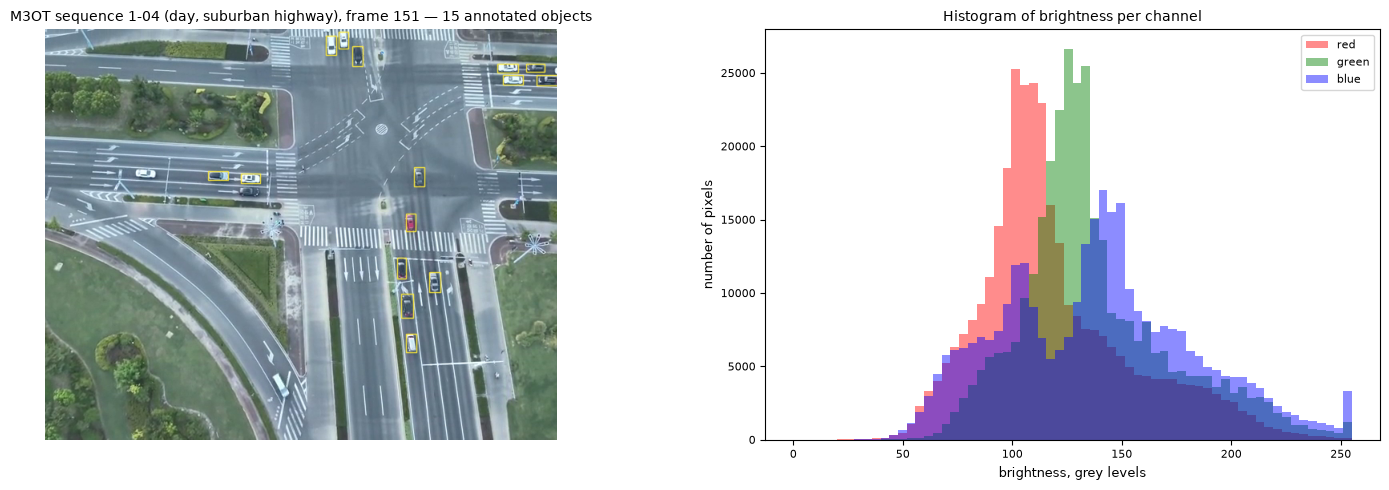

,Value
"shape (H, W, C)","(512, 640, 3)"
data type,uint8
range of values,9 … 255
"mean of R, G, B","119.4, 138.0, 139.3"
"size in memory, KB",960
"size of the file, KB",574
compression ratio of the file,1.7


In [3]:
#@title 1.3.3 Visible frame of a UAV (code shown) { run: "auto" }
SOURCE = "M3OT (DJI Mavic 3T, vertical view)" #@param ["VisDrone (oblique view over a city)", "M3OT (DJI Mavic 3T, vertical view)", "Kust4K (UAV over a road)", "own frame: upload", "own frame: file on Google Drive", "own frame: URL"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}
SHOW_ANNOTATION = True #@param {type:"boolean"}
OWN_PATH = "/content/drive/MyDrive/AITBC/data/images/frame.jpg" #@param {type:"string"}
OWN_URL = "" #@param {type:"string"}

M3OT_VIEWS = [("1-04", 150), ("1-09", 300), ("1-01", 700), ("1-07", 200), ("1-05", 150), ("1-03", 240), ("1-06", 300), ("1-08", 300)]
objs, path = [], None
if SOURCE.startswith("VisDrone"):
    name = vis.CURATED[FRAME_NUMBER - 1]
    path = vis.z.get(f"VisDrone2019-DET-val/images/{name}.jpg")
    _, objs = vis.load(name)
    caption = f"VisDrone {name}"
elif SOURCE.startswith("M3OT"):
    seq, k = M3OT_VIEWS[FRAME_NUMBER - 1]
    path = m3ot.prefetch(seq, "rgb", start=k, count=1)[0]
    objs = m3ot.objects(m3ot.tracks(seq, "rgb"), k + 1)
    caption = f"M3OT sequence {seq} ({m3ot.SEQUENCES[seq]}), frame {k + 1}"
elif SOURCE.startswith("Kust4K"):
    fid = kust.DAY[FRAME_NUMBER - 1]
    kust.prefetch([fid])
    path = kust._zip("rgb").get(fid + ".png")
    caption = f"Kust4K {fid}"
elif SOURCE.endswith("upload"):
    if not IN_COLAB:
        raise RuntimeError("upload works only in Google Colab")
    from google.colab import files
    up = files.upload()
    path = os.path.join(WORK_DIR, next(iter(up)))
    caption = "own frame"
elif SOURCE.endswith("Google Drive"):
    if IN_COLAB and OWN_PATH.startswith("/content/drive") and not os.path.isdir("/content/drive/MyDrive"):
        from google.colab import drive
        drive.mount("/content/drive")
    path, caption = OWN_PATH, "own frame"
else:
    path = aitbc.fetch(OWN_URL, os.path.join(WORK_DIR, "own_frame" + os.path.splitext(OWN_URL.split("?")[0])[1]))
    caption = "own frame"

bgr = cv2.imread(path, cv2.IMREAD_COLOR)            # OpenCV reads colour images in the order B, G, R
if bgr is None:
    raise IOError(f"OpenCV cannot read {path}")
frame_eo = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)     # Matplotlib expects R, G, B
FRAME_EO, FRAME_EO_NAME = frame_eo, caption
shown = aitbc.draw_boxes(frame_eo, objs, {"vehicle": (255, 235, 59)} if objs and objs[0]["cls"] == "vehicle" else vis.COLORS,
                         labels=False) if (SHOW_ANNOTATION and objs) else frame_eo
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax[0].imshow(shown)
ax[0].set_title(caption + (f" — {len(objs)} annotated objects" if objs else ""), fontsize=10)
ax[0].axis("off")
for c, col in enumerate(("red", "green", "blue")):
    ax[1].hist(frame_eo[..., c].ravel(), bins=64, range=(0, 255), color=col, alpha=0.45, label=col)
ax[1].set_xlabel("brightness, grey levels")
ax[1].set_ylabel("number of pixels")
ax[1].legend()
ax[1].set_title("Histogram of brightness per channel")
plt.tight_layout()
plt.show()
h, w = frame_eo.shape[:2]
display(pd.DataFrame({"Value": [str(frame_eo.shape), str(frame_eo.dtype), f"{frame_eo.min()} … {frame_eo.max()}",
                                ", ".join(f"{v:.1f}" for v in frame_eo.reshape(-1, 3).mean(0)),
                                f"{frame_eo.nbytes / 1024:.0f}", f"{os.path.getsize(path) / 1024:.0f}",
                                f"{frame_eo.nbytes / os.path.getsize(path):.1f}"]},
                     index=["shape (H, W, C)", "data type", "range of values", "mean of R, G, B",
                            "size in memory, KB", "size of the file, KB", "compression ratio of the file"]))

## Task 1.3.4. Thermal frame and its comparison with the visible frame

**Purpose.** To load a thermal frame of the same scene as the visible one, to establish the palette of the thermal channel and to compare the two channels: what each channel shows, their brightness statistics, and how well their structures coincide.

**Parameters.**
- `PAIR` — source of a synchronised pair: M3OT (visible and thermal camera of one DJI Mavic 3T; day, dusk, night) or Kust4K (registered pair of a UAV over a road; night and day pairs alternate).
- `FRAME_NUMBER` — pair of the selected source.
- `VIEW` — side by side, blend of the two channels with a slider, or edges of both channels in one image (red — visible, green — thermal; yellow — coinciding edges).
- `BLEND` — share of the thermal channel in the blend.
- `THERMAL_VIEW` — the thermal frame as recorded in the data set, or converted to the convention "warm = bright" (white-hot), which is used in the following lessons for the detection of warm objects.
- `CHECK_ALL_PAIRS` — the palette check for all eight pairs of the selected source.

**Palette of a thermal frame.** A thermal camera converts the temperature of the scene into brightness through a palette. The two grey palettes are white-hot (warm = bright; HIT-UAV) and black-hot (warm = dark); pseudo-colour palettes map the temperature to colours (Kust4K: from purple, cold, to yellow, warm). When the description of a data set does not state the palette, it is established from the scene. In a road scene the asphalt is, as a rule, warmer than vegetation: by day it absorbs most of the solar radiation, at night it gives off the heat stored during the day, while vegetation is cooled by the evaporation of water from the leaves. The road surface is taken around the annotated vehicles (M3OT) or from the segmentation labels (Kust4K). The vegetation is taken by the green colour of the visible frame, with the excess-green index $ExG = (2G - R - B)/(R + G + B) > 0.12$ (M3OT), or from the labels (Kust4K). A road darker than the vegetation by more than 15 grey levels indicates the black-hot palette, a brighter road — the white-hot convention.

**Expected result.** Panels of the two channels, a table of their properties and the result of the palette check. For every channel the table shows the mean, the standard deviation (contrast) and the **entropy** of the brightness histogram

$$H = -\sum_{k=0}^{255} p_k \log_2 p_k, \tag{2}$$

bit, where $p_k$ is the share of pixels with the brightness $k$. The entropy shows how many brightness levels are effectively used: 8 bit — all 256 levels equally, low values — a dark or flat image. The **sharpness** is the variance of the Laplacian (Lesson 1.1).

**What to observe.** At night the visible frame of M3OT (sequence 1-02) is dark and has a low entropy, while the thermal frame keeps the full range. In the thermal frames of M3OT the road surface is dark, while vegetation, fields and vehicles are bright: the thermal channel of M3OT is recorded in the black-hot palette, therefore the dark asphalt is warmer than the vegetation, and the bright vehicles are cooler than the road. Kust4K shows the opposite order of brightness for the same order of temperatures. The rule "asphalt is warmer than vegetation" has exceptions: in the day pair 00355D of Kust4K (pair 8; low sun, long shadows) the sunlit tree crowns are warmer than the road, therefore the palette is established on several frames (`CHECK_ALL_PAIRS`). In the edge view the edges of roads and buildings coincide only approximately: the two cameras have different lenses, and the residual shift between the channels is measured in task 1.4.4.

**Control question 4.** Name two objects that are visible in the thermal frame but not in the visible frame, and two details that are visible only in the visible frame. Which palette does the thermal channel of M3OT use, and which observation in the frame shows it?

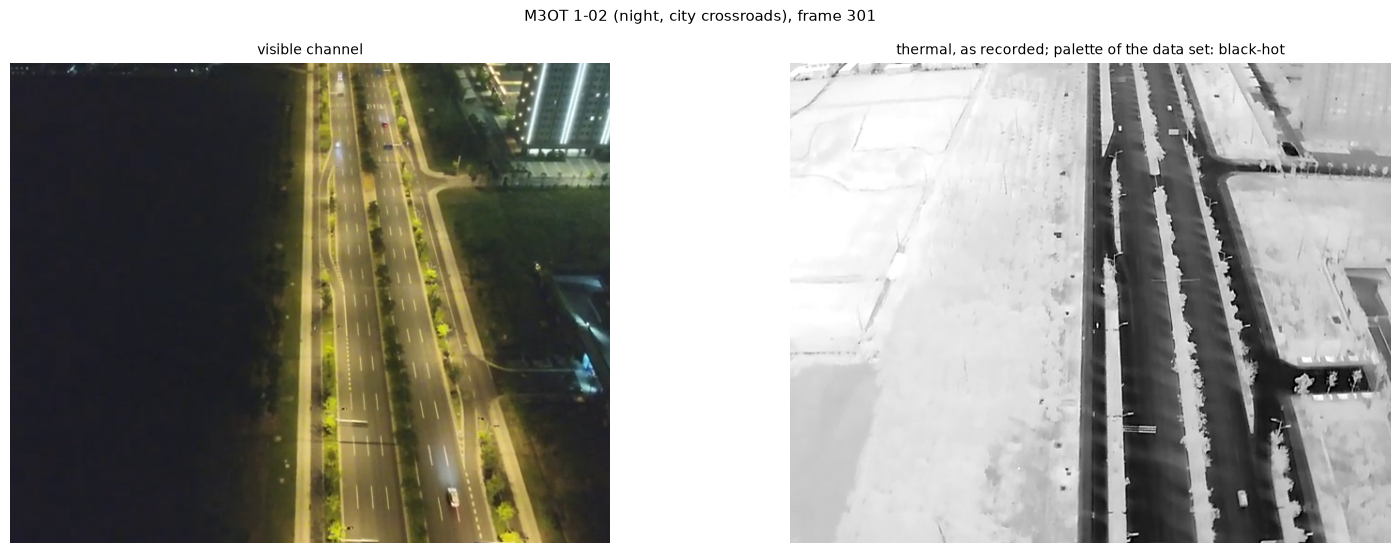

,mean,std,entropy_bit,sharpness,shape
channel,,,,,
visible,67.6,47.7,6.22,137,"(512, 640, 3)"
"thermal, as recorded",179.1,68.9,7.03,497,"(512, 640, 3)"


,Value
palette in the course library,black-hot
road surface: median brightness as recorded,51 (4270 px)
vegetation: median brightness as recorded,210 (7952 px)
palette established from the scene,road darker than vegetation: black-hot (warm = dark)


In [4]:
#@title 1.3.4 Thermal frame and comparison with the visible frame [auto] { run: "auto", display-mode: "form" }
PAIR = "M3OT (DJI Mavic 3T: day, dusk, night)" #@param ["M3OT (DJI Mavic 3T: day, dusk, night)", "Kust4K (UAV over a road: day, night)"]
FRAME_NUMBER = 1 #@param {type:"slider", min:1, max:8, step:1}
VIEW = "side by side" #@param ["side by side", "blend", "edges of both channels"]
BLEND = 0.5 #@param {type:"slider", min:0, max:1, step:0.05}
THERMAL_VIEW = "as recorded" #@param ["as recorded", "warm = bright (white-hot)"]
CHECK_ALL_PAIRS = False #@param {type:"boolean"}

M3OT_PAIRS = [("1-02", 300), ("1-04", 150), ("1-06", 300), ("1-08", 300), ("1-09", 300), ("1-01", 700), ("1-03", 240), ("1-05", 150)]
KUST_PAIRS = ("02566N", "00031D", "02807N", "00580D", "03135N", "00990D", "03895N", "00355D")


def load_pair(number):
    # visible frame, thermal frame, palette, road and vegetation masks and caption of pair `number`
    if PAIR.startswith("M3OT"):
        seq, k = M3OT_PAIRS[number - 1]
        eo_ = m3ot.frames(seq, "rgb", start=k, count=1)[0]
        ir_ = m3ot.frames(seq, "ir", start=k, count=1)[0]
        boxes = [o["box"] for o in m3ot.objects(m3ot.tracks(seq, "ir"), k + 1)]
        road_ = aitbc.surroundings_mask(ir_.shape, boxes)                  # road surface around the vehicles
        veg_ = aitbc.vegetation_mask(eo_)                                    # green colour of the visible frame
        return eo_, ir_, m3ot.PALETTE, road_, veg_, f"M3OT {seq} ({m3ot.SEQUENCES[seq]}), frame {k + 1}"
    p = kust.pair(KUST_PAIRS[number - 1])
    return (p["rgb"], p["tir"], kust.PALETTE, p["labels"] == 1, p["labels"] == 6,
            f"Kust4K {p['id']} ({'night' if p['night'] else 'day'})")


def entropy(img):
    hist = np.bincount(aitbc.gray(img).ravel(), minlength=256).astype(float)
    p = hist[hist > 0] / hist.sum()
    return float(-(p * np.log2(p)).sum())                                   # formula (2)


eo, ir, palette, road, veg, caption = load_pair(FRAME_NUMBER)
FRAME_IR = ir                                                               # saved as recorded in task 1.3.5
WARM_BRIGHT = THERMAL_VIEW.startswith("warm")
ir_show = aitbc.to_white_hot(ir, palette) if WARM_BRIGHT else ir
ir_name = "thermal, warm = bright" if WARM_BRIGHT else "thermal, as recorded"

if VIEW == "side by side":
    panels = [(eo, "visible channel"), (ir_show, f"{ir_name}; palette of the data set: {palette}")]
elif VIEW == "blend":
    panels = [(((1 - BLEND) * eo.astype(np.float32) + BLEND * ir_show.astype(np.float32)).astype(np.uint8),
               f"blend: {1 - BLEND:.2f}·visible + {BLEND:.2f}·thermal")]
else:
    e1 = cv2.Canny(cv2.GaussianBlur(aitbc.gray(eo), (5, 5), 0), 60, 140)
    e2 = cv2.Canny(cv2.GaussianBlur(aitbc.gray(ir_show), (5, 5), 0), 60, 140)
    edges = np.zeros_like(eo)
    edges[..., 0], edges[..., 1] = e1, e2
    panels = [(edges, "edges: red — visible, green — thermal, yellow — both")]
fig, ax = plt.subplots(1, len(panels), figsize=(8 * len(panels), 5.6), squeeze=False)
for a, (im_, ti) in zip(ax[0], panels):
    a.imshow(im_)
    a.set_title(ti, fontsize=10)
    a.axis("off")
fig.suptitle(caption, fontsize=11)
plt.tight_layout()
plt.show()

rows = []
for name, im_ in (("visible", eo), (ir_name, ir_show)):
    g = aitbc.gray(im_)
    rows.append(dict(channel=name, mean=round(float(g.mean()), 1), std=round(float(g.std()), 1),
                     entropy_bit=round(entropy(im_), 2), sharpness=round(aitbc.sharpness(im_)), shape=str(im_.shape)))
display(pd.DataFrame(rows).set_index("channel"))

chk = aitbc.palette_check(ir, road, veg)                                    # brightness as recorded
pd.set_option("display.max_colwidth", 100)                                  # show the conclusions in full
display(pd.DataFrame({"Value": [palette,
                                f"{chk['road_median']:.0f} ({chk['road_pixels']} px)",
                                f"{chk['vegetation_median']:.0f} ({chk['vegetation_pixels']} px)",
                                chk["verdict"]]},
                     index=["palette in the course library", "road surface: median brightness as recorded",
                            "vegetation: median brightness as recorded", "palette established from the scene"]))

if CHECK_ALL_PAIRS:
    rows = []
    for n in range(1, 9):
        e_, i_, pal_, r_, v_, cap_ = load_pair(n)
        c_ = aitbc.palette_check(i_, r_, v_)
        rows.append(dict(pair=n, frame=cap_, road=c_["road_median"], vegetation=c_["vegetation_median"],
                         conclusion=c_["verdict"]))
    tab = pd.DataFrame(rows).set_index("pair")
    display(tab)
    print("Conclusions over the eight pairs:")
    print(tab.conclusion.value_counts().to_string())

## Task 1.3.5. Structure of the project on Google Drive

**Purpose.** To connect Google Drive, to check (and, if necessary, create) the course project `data / frames / models / outputs` and to save in it the frames of tasks 1.3.3 and 1.3.4 together with the versions of the libraries.

**Parameters.**
- `USE_DRIVE` — keep the project on Google Drive (Colab asks for access to the Google account); otherwise it is created on the session disk and lost at the end of the session.
- `PROJECT_PATH` — folder of the project on Google Drive (the same as in Notebook 01).
- `SAVE_FRAMES` — save the visible frame (`data/images`) and the thermal frame (`data/thermal`) of tasks 1.3.3–1.3.4.

**Expected result.** The tree of the project with the new files and the updated `project.json` (versions of the libraries of task 1.3.2, date, list of the lessons done).

**Control question 5.** Why are the frames saved in PNG and not in JPEG? When is JPEG acceptable?

In [5]:
#@title 1.3.5 Project structure on Google Drive and the first saved frames { display-mode: "form" }
USE_DRIVE = True #@param {type:"boolean"}
PROJECT_PATH = "AITBC/AITBC_project" #@param {type:"string"}
SAVE_FRAMES = True #@param {type:"boolean"}

if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    PROJECT_ROOT = os.path.join("/content/drive/MyDrive", PROJECT_PATH)
else:
    PROJECT_ROOT = os.path.join(WORK_DIR, PROJECT_PATH)
    if USE_DRIVE:
        print("Google Drive is available only in Google Colab; the project is created in", PROJECT_ROOT)
SUBDIRS = ["data/images", "data/video", "data/thermal", "data/annotations", "frames/visible", "frames/thermal",
           "models", "outputs/figures", "outputs/video", "outputs/reports"]
created = [d for d in SUBDIRS if not os.path.isdir(os.path.join(PROJECT_ROOT, d))]
for d in SUBDIRS:
    os.makedirs(os.path.join(PROJECT_ROOT, d), exist_ok=True)
print(f"Project: {PROJECT_ROOT} ({'created now: ' + ', '.join(created) if created else 'structure is complete'})")


def update_project_json(lesson, extra=None):
    path = os.path.join(PROJECT_ROOT, "project.json")
    meta = json.load(open(path, encoding="utf-8")) if os.path.exists(path) else {"project": os.path.basename(PROJECT_ROOT)}
    meta.setdefault("lessons", [])
    if lesson not in meta["lessons"]:
        meta["lessons"].append(lesson)
    meta["updated"] = time.strftime("%Y-%m-%d %H:%M:%S")
    meta["versions"] = {k: v for k, v in VERSIONS["Installed"].items()} if "VERSIONS" in globals() else {}
    meta["aitbc"] = aitbc.__version__
    meta.update(extra or {})
    with open(path, "w", encoding="utf-8") as fh:
        json.dump(meta, fh, indent=2, ensure_ascii=False)
    return meta


saved = []
if SAVE_FRAMES and "FRAME_EO" in globals():
    stamp = time.strftime("%Y%m%d")
    p1 = os.path.join(PROJECT_ROOT, "data", "images", f"lesson13_eo_{stamp}.png")
    cv2.imwrite(p1, cv2.cvtColor(FRAME_EO, cv2.COLOR_RGB2BGR))
    saved.append(p1)
    if "FRAME_IR" in globals():
        p2 = os.path.join(PROJECT_ROOT, "data", "thermal", f"lesson13_ir_{stamp}.png")
        cv2.imwrite(p2, cv2.cvtColor(FRAME_IR, cv2.COLOR_RGB2BGR))
        saved.append(p2)
meta = update_project_json("1.3", {"lesson_1_3_frames": [os.path.relpath(p, PROJECT_ROOT) for p in saved],
                                   "lesson_1_3_source": globals().get("FRAME_EO_NAME", "")})


def print_tree(path, prefix="", depth=0, max_files=6):
    entries = sorted(os.listdir(path), key=lambda e: (not os.path.isdir(os.path.join(path, e)), e))
    files = [e for e in entries if not os.path.isdir(os.path.join(path, e))]
    shown = [e for e in entries if os.path.isdir(os.path.join(path, e))] + files[:max_files]
    for i, e in enumerate(shown):
        last = i == len(shown) - 1 and len(files) <= max_files
        full = os.path.join(path, e)
        size = "" if os.path.isdir(full) else f"  ({os.path.getsize(full) / 1024:.0f} KB)"
        print(prefix + ("└── " if last else "├── ") + e + ("/" if os.path.isdir(full) else "") + size)
        if os.path.isdir(full):
            print_tree(full, prefix + ("    " if last else "│   "), depth + 1, max_files)
    if len(files) > max_files:
        print(prefix + f"└── … {len(files) - max_files} more files")


print(PROJECT_ROOT + "/")
print_tree(PROJECT_ROOT)
print("project.json: lessons", meta["lessons"], "| updated", meta["updated"])

Google Drive is available only in Google Colab; the project is created in /content/AITBC/AITBC_project
Project: /content/AITBC/AITBC_project (structure is complete)
/content/AITBC/AITBC_project/
├── data/
│   ├── annotations/
│   ├── images/
│   │   └── lesson13_eo_20261025.png  (574 KB)
│   ├── thermal/
│   │   └── lesson13_ir_20261025.png  (422 KB)
│   └── video/
│       ├── hituav_60m-30_1.mov  (9625 KB)
│       ├── m3ot_1-02_eo_0100_50.avi  (1394 KB)
│       ├── m3ot_1-02_ir_0100_50.avi  (1758 KB)
│       ├── m3ot_1-04_eo_0000_200.mp4  (4008 KB)
│       ├── m3ot_1-04_ir_0000_200.mp4  (3205 KB)
│       ├── m3ot_1-09_eo_0598_2.mp4  (93 KB)
│       └── … 1 more files
├── frames/
│   ├── thermal/
│   │   ├── m3ot_1-02/
│   │   │   ├── frames.csv  (0 KB)
│   │   │   └── m3ot_1-02_ir_000000.png  (167 KB)
│   │   ├── m3ot_1-04/
│   │   │   ├── frames.csv  (3 KB)
│   │   │   ├── m3ot_1-04_ir_000000.png  (196 KB)
│   │   │   ├── m3ot_1-04_ir_000005.png  (224 KB)
│   │   │   ├── m3ot_1-04_ir

### Report of Lesson 1.3

Double-click this cell and write the answers.

1. Runtime of the notebook (CPU or GPU, name of the GPU) and the measured speeds of task 1.3.1:
2. Answer to control question 1:
3. Versions of Python, OpenCV and PyTorch:
4. Answer to control question 2:
5. Source, size and data type of the visible frame; answer to control question 3:
6. Entropy and contrast of the visible and thermal frames by day and at night; palette of the thermal channel of M3OT and of Kust4K established from the scene; answer to control question 4:
7. Path of the project on Google Drive; answer to control question 5:

---
# Lesson 1.4 (Practical class). Processing of video streams of UAVs and ground robotic platforms

**Learning questions**
1. Connection of Google Drive to Colab and loading of a video fragment from the electro-optical system of a UAV.
2. Decomposition of a video stream into separate frames with a given sampling rate.
3. Display of the sequence of frames as a grid for preliminary visual analysis.
4. Processing of a thermal video fragment by the same method.
5. Saving of the formed sets of frames in the corresponding folders of the project.

**Result of the lesson.** Visible and thermal video fragments of a UAV in `data/video`, the frame sets extracted from them with the chosen sampling rate in `frames/visible` and `frames/thermal` with an index table (`frames.csv`), grids of frames in `outputs/figures`, and the measured offset between the visible and the thermal channel.

**Video data of the lesson.**
- **M3OT** — the visible and the thermal camera of a DJI Mavic 3T record the same scene at 10 frames per second. The data set stores the sequences as numbered frames; task 1.4.1 assembles them into a video file, as the stream of a UAV is recorded on board, and the following tasks work with the video file.
- **HIT-UAV** — five thermal videos of a DJI Matrice M210 V2 with a Zenmuse XT2 camera (7.5 frames per second, H.264), recorded as they are.
- **Own video** of the participant from Google Drive (any format that OpenCV reads: MP4, AVI, MOV).

## Task 1.4.1. Google Drive and a video fragment of a UAV

**Purpose.** To obtain a video fragment of a UAV, to save it in `data/video` of the project and to read its properties with `cv2.VideoCapture`.

**Parameters.**
- `SOURCE` — M3OT visible video (assembled from the frames of a sequence), HIT-UAV thermal video, or own video from Google Drive (`OWN_VIDEO`).
- `SEQUENCE`, `START_FRAME`, `N_FRAMES` — sequence of M3OT and the fragment of it (10 frames = 1 s). Every frame is a PNG file of about 0.6 MB: at the first run 200 visible frames (task 1.4.1) and 200 thermal frames (task 1.4.4) mean about 230 MB of download; later runs read the frames from the cache (`CACHE_ON_DRIVE`, task 1.3.2, keeps it between sessions).
- `CODEC` — codec of the written file: `mp4v` (MPEG-4 Part 2, file .mp4) or `MJPG` (Motion JPEG, file .avi, every frame is a JPEG image: larger files, simple random access).

**Code (shown).** The video is written with `cv2.VideoWriter` and read back with `cv2.VideoCapture`; the properties are read with `cap.get(cv2.CAP_PROP_...)`.

**Expected result.** A table of the properties of the video file (frame rate, number of frames, duration, size, codec, data rate) and three frames of it. The data rate of a video file is

$$R = \frac{8 S}{T}, \tag{3}$$

bit/s, where $S$ is the size of the file in bytes and $T$ the duration in seconds. It is compared with the rate of the uncompressed stream $R_0 = W \cdot H \cdot 3 \cdot 8 \cdot f$ for frames W × H px at f frames per second; the ratio $R_0 / R$ is the compression ratio of the codec.

**Control question 6.** Why does a video file take tens of times less space than the same number of PNG frames? What is lost during this compression?

,Value
Property,
file,data\video\m3ot_1-04_eo_0000_200.mp4
codec (FourCC),FMP4
"frame size W x H, px",640 x 512
"frame rate f, frames/s",10.00
number of frames,200
"duration T, s",20.0
"file size S, MB",4.10
"data rate R, Mbit/s (3)",1.64
"uncompressed rate R0, Mbit/s",78.6


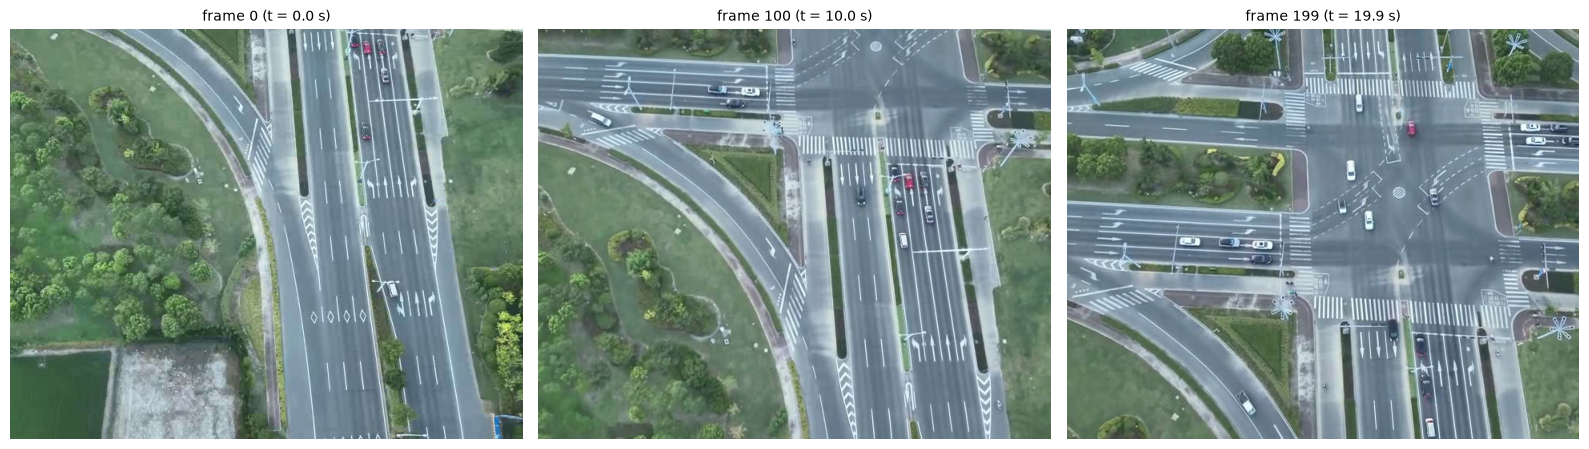

In [6]:
#@title 1.4.1 Video fragment of a UAV in data/video (code shown) { display-mode: "form" }
SOURCE = "M3OT visible video (DJI Mavic 3T)" #@param ["M3OT visible video (DJI Mavic 3T)", "HIT-UAV thermal video (Zenmuse XT2)", "own video from Google Drive"]
SEQUENCE = "1-04" #@param ["1-01", "1-02", "1-03", "1-04", "1-05", "1-06", "1-07", "1-08", "1-09"]
START_FRAME = 0 #@param {type:"integer"}
N_FRAMES = 200 #@param {type:"slider", min:20, max:600, step:10}
HIT_VIDEO = "60m-30_1.mov" #@param ["60m-30_1.mov", "60m-40_3.mov", "70m-90_1.mov", "120m-30_3.mov", "130m-60_3.mov"]
OWN_VIDEO = "/content/drive/MyDrive/AITBC/data/video/my_video.mp4" #@param {type:"string"}
CODEC = "mp4v" #@param ["mp4v", "MJPG"]

video_dir = os.path.join(PROJECT_ROOT, "data", "video")
ext = ".mp4" if CODEC == "mp4v" else ".avi"
if SOURCE.startswith("M3OT"):
    n_total = m3ot.n_frames(SEQUENCE, "rgb")
    start = int(np.clip(START_FRAME, 0, n_total - 2))
    count = int(min(N_FRAMES, n_total - start))
    frames = m3ot.frames(SEQUENCE, "rgb", start=start, count=count)
    VIDEO_EO = os.path.join(video_dir, f"m3ot_{SEQUENCE}_eo_{start:04d}_{count}{ext}")
    aitbc.write_video(VIDEO_EO, frames, fps=m3ot.CAMERA["fps"], codec=CODEC)     # cv2.VideoWriter inside
    png_size = sum(os.path.getsize(p) for p in m3ot.prefetch(SEQUENCE, "rgb", start=start, count=count))
    VIDEO_EO_SOURCE = dict(dataset="M3OT", sequence=SEQUENCE, channel="visible", start_frame=start + 1, frames=count)
    del frames
elif SOURCE.startswith("HIT-UAV"):
    src = hit.video(HIT_VIDEO)
    VIDEO_EO = os.path.join(video_dir, "hituav_" + HIT_VIDEO)
    shutil.copy2(src, VIDEO_EO)
    png_size = None
    VIDEO_EO_SOURCE = dict(dataset="HIT-UAV", video=HIT_VIDEO, channel="thermal")
else:
    if IN_COLAB and OWN_VIDEO.startswith("/content/drive") and not os.path.isdir("/content/drive/MyDrive"):
        from google.colab import drive
        drive.mount("/content/drive")
    if not os.path.isfile(OWN_VIDEO):
        raise FileNotFoundError(f"{OWN_VIDEO} not found: copy the video to Google Drive and give its path in OWN_VIDEO")
    VIDEO_EO, png_size = OWN_VIDEO, None
    VIDEO_EO_SOURCE = dict(dataset="own video", path=OWN_VIDEO)

cap = cv2.VideoCapture(VIDEO_EO)
if not cap.isOpened() or cap.get(cv2.CAP_PROP_FPS) <= 0:
    raise IOError(f"OpenCV cannot read the video {VIDEO_EO}: convert it to MP4 (H.264) or AVI (MJPG)")
fps = cap.get(cv2.CAP_PROP_FPS)
n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
codec = int(cap.get(cv2.CAP_PROP_FOURCC)).to_bytes(4, "little").decode("latin-1", "replace")
samples = []
for k in (0, n // 2, max(n - 1, 0)):
    cap.set(cv2.CAP_PROP_POS_FRAMES, k)
    ok, f = cap.read()
    if ok:
        samples.append((k, cv2.cvtColor(f, cv2.COLOR_BGR2RGB)))
cap.release()
S = os.path.getsize(VIDEO_EO)
T = n / fps if fps else float("nan")
R = 8 * S / T                                                           # formula (3)
R0 = w * h * 3 * 8 * fps
rows = [("file", os.path.relpath(VIDEO_EO, PROJECT_ROOT) if VIDEO_EO.startswith(PROJECT_ROOT) else VIDEO_EO),
        ("codec (FourCC)", codec), ("frame size W x H, px", f"{w} x {h}"), ("frame rate f, frames/s", f"{fps:.2f}"),
        ("number of frames", n), ("duration T, s", f"{T:.1f}"), ("file size S, MB", f"{S / 1e6:.2f}"),
        ("data rate R, Mbit/s (3)", f"{R / 1e6:.2f}"), ("uncompressed rate R0, Mbit/s", f"{R0 / 1e6:.1f}"),
        ("compression ratio R0 / R", f"{R0 / R:.0f}")]
if png_size:
    rows.append(("same frames as PNG files, MB", f"{png_size / 1e6:.1f}"))
display(pd.DataFrame(rows, columns=["Property", "Value"]).set_index("Property"))
fig, ax = plt.subplots(1, len(samples), figsize=(16, 4.4))
for a, (k, f) in zip(np.atleast_1d(ax), samples):
    a.imshow(f)
    a.set_title(f"frame {k} (t = {k / fps:.1f} s)", fontsize=10)
    a.axis("off")
plt.tight_layout()
plt.show()

## Task 1.4.2. Decomposition of the video stream into frames with a given sampling rate

**Purpose.** To extract frames from the video file with a chosen sampling rate and to estimate how the choice of the rate changes the number of frames, their similarity and the motion between them.

With the frame rate of the video $f$ and the required sampling rate $f_s \le f$, every $N$-th frame is taken:

$$N = \operatorname{round}\left(\frac{f}{f_s}\right), \qquad f_s' = \frac{f}{N}, \qquad \Delta t = \frac{N}{f}, \tag{4}$$

where $f_s'$ is the actual sampling rate and $\Delta t$ is the time between the extracted frames. For a video of $n$ frames the set contains $\lceil n/N \rceil$ frames.

**Parameters.**
- `SAMPLING_RATE_HZ` — required sampling rate $f_s$, frames per second.
- `MAX_FRAMES` — maximum number of extracted frames.
- `RESIZE_WIDTH` — width of the extracted frames, px (0 = original size); a smaller width reduces the volume of the set.

**Code (shown).** The video is read frame by frame with a generator (`aitbc.iter_video`), therefore a long video does not fill the memory.

**Output.** The table of the extraction: $N$, $f_s'$, $\Delta t$ (4), number and volume of the frames; two plots for the extracted frames:
1. the mean absolute difference of successive frames (similarity: small values mean almost repeated frames);
2. the displacement of the image between successive extracted frames, estimated by phase correlation (motion of the camera).

**What to observe.** With a high sampling rate successive frames are almost identical: the set is large but carries little new information. With a low rate the displacement between frames grows; when it reaches a large part of the frame width, neighbouring frames no longer overlap, and stabilisation, mosaicking or tracking (Topics 3 and 5) become impossible. The sampling rate is chosen as a compromise between the volume of the set and the overlap of the frames. This is how the data sets of the course were made: Kust4K and HIT-UAV took every 15th frame of their videos.

**Control question 7.** A video of 30 frames per second is decomposed with $f_s$ = 4 Hz. What are $N$, $f_s'$ and $\Delta t$? How many frames does a 2-minute video give?

,Value
"frame rate of the video f, frames/s",10.00
"required sampling rate f_s, Hz",2.00
"step N, frames (4)",5
"actual sampling rate f_s', Hz (4)",2.000
"time between extracted frames Δt, s (4)",0.500
frames in the video,200
frames extracted,40
frames of the whole video at this step,40
shape of an extracted frame,"(512, 640, 3)"
"volume of the set in memory, MB",39.3


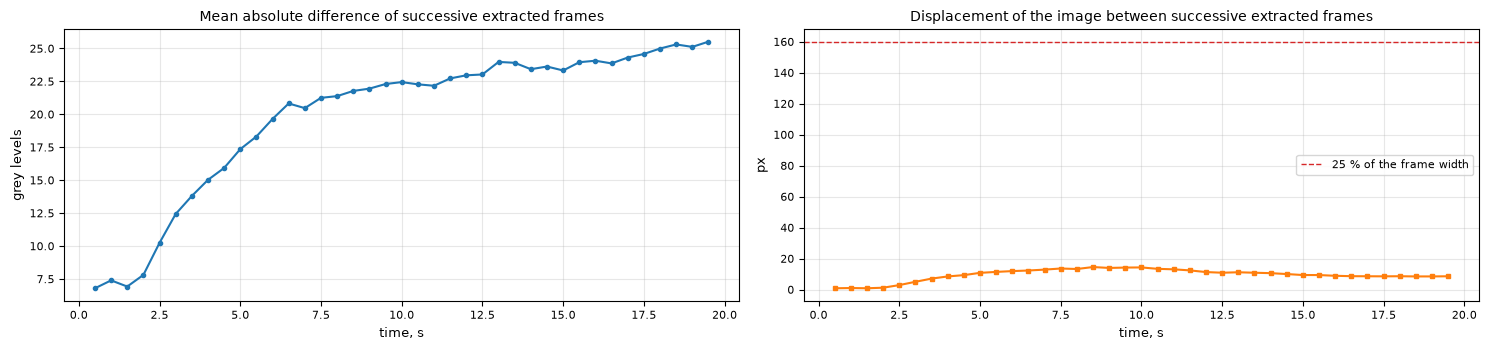

Median difference 22.27 grey levels; median displacement 10.0 px, maximum 14.5 px per step of 0.50 s


In [7]:
#@title 1.4.2 Frames with a given sampling rate (code shown) { run: "auto" }
SAMPLING_RATE_HZ = 2.0 #@param {type:"slider", min:0.2, max:30, step:0.2}
MAX_FRAMES = 60 #@param {type:"slider", min:6, max:300, step:6}
RESIZE_WIDTH = 0 #@param {type:"slider", min:0, max:1280, step:160}

info = aitbc.video_info(VIDEO_EO)
f = info["fps"]
N = max(1, int(round(f / SAMPLING_RATE_HZ)))                     # formula (4)
fs_actual, dt = f / N, N / f
EXTRACTED_EO = []                                                # list of (frame number, time s, frame)
for k, t, frame in aitbc.iter_video(VIDEO_EO, every_n=N, max_frames=MAX_FRAMES):
    if RESIZE_WIDTH:
        frame = cv2.resize(frame, (RESIZE_WIDTH, int(round(frame.shape[0] * RESIZE_WIDTH / frame.shape[1]))),
                           interpolation=cv2.INTER_AREA)
    EXTRACTED_EO.append((k, t, frame))
EXTRACTION_EO = dict(video=VIDEO_EO, fps=f, N=N, fs=fs_actual, dt=dt, resize_width=RESIZE_WIDTH)
diffs = [aitbc.frame_difference(EXTRACTED_EO[i - 1][2], EXTRACTED_EO[i][2]) for i in range(1, len(EXTRACTED_EO))]
shifts = [np.hypot(*aitbc.global_shift(aitbc.gray(EXTRACTED_EO[i - 1][2]), aitbc.gray(EXTRACTED_EO[i][2])))
          for i in range(1, len(EXTRACTED_EO))]
vol = sum(fr.nbytes for _, _, fr in EXTRACTED_EO)
display(pd.DataFrame({"Value": [f"{f:.2f}", f"{SAMPLING_RATE_HZ:.2f}", N, f"{fs_actual:.3f}", f"{dt:.3f}",
                                f"{info['frames']}", len(EXTRACTED_EO), f"{math.ceil(info['frames'] / N)}",
                                str(EXTRACTED_EO[0][2].shape), f"{vol / 1e6:.1f}"]},
                     index=["frame rate of the video f, frames/s", "required sampling rate f_s, Hz", "step N, frames (4)",
                            "actual sampling rate f_s', Hz (4)", "time between extracted frames Δt, s (4)",
                            "frames in the video", "frames extracted", "frames of the whole video at this step",
                            "shape of an extracted frame", "volume of the set in memory, MB"]))
if len(EXTRACTED_EO) > 1:
    tt = [t for _, t, _ in EXTRACTED_EO[1:]]
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
    ax[0].plot(tt, diffs, "o-", ms=3)
    ax[0].set_xlabel("time, s")
    ax[0].set_ylabel("grey levels")
    ax[0].set_title("Mean absolute difference of successive extracted frames")
    ax[1].plot(tt, shifts, "s-", ms=3, color="C1")
    ax[1].axhline(0.25 * EXTRACTED_EO[0][2].shape[1], color="C3", ls="--", lw=1, label="25 % of the frame width")
    ax[1].set_xlabel("time, s")
    ax[1].set_ylabel("px")
    ax[1].set_title("Displacement of the image between successive extracted frames")
    ax[1].legend()
    for a in ax:
        a.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f"Median difference {np.median(diffs):.2f} grey levels; median displacement {np.median(shifts):.1f} px, "
          f"maximum {np.max(shifts):.1f} px per step of {dt:.2f} s")

## Task 1.4.3. Grid of frames for preliminary visual analysis

**Purpose.** To display the extracted frames as a grid (*contact sheet*) and to use it for a quick review of the fragment: changes of the scene, motion of the camera, presence of objects, defective frames.

**Parameters.**
- `COLUMNS` — number of columns of the grid; `FRAMES_IN_GRID` — number of frames (taken uniformly from the extracted set);
- `SHOW_TIME` — label of every frame with its number and time;
- `SHOW_TRACKS` — boxes of the annotated vehicles (M3OT only).

**Output.** The grid of frames; a table of the frames with the mean brightness, the sharpness (variance of the Laplacian) and the number of annotated vehicles; frames whose sharpness is below half of the median are marked as possibly blurred.

**Control question 8.** Which changes in the scene and in the motion of the camera can be found in the grid? Which frames would be removed from a training set, and why?

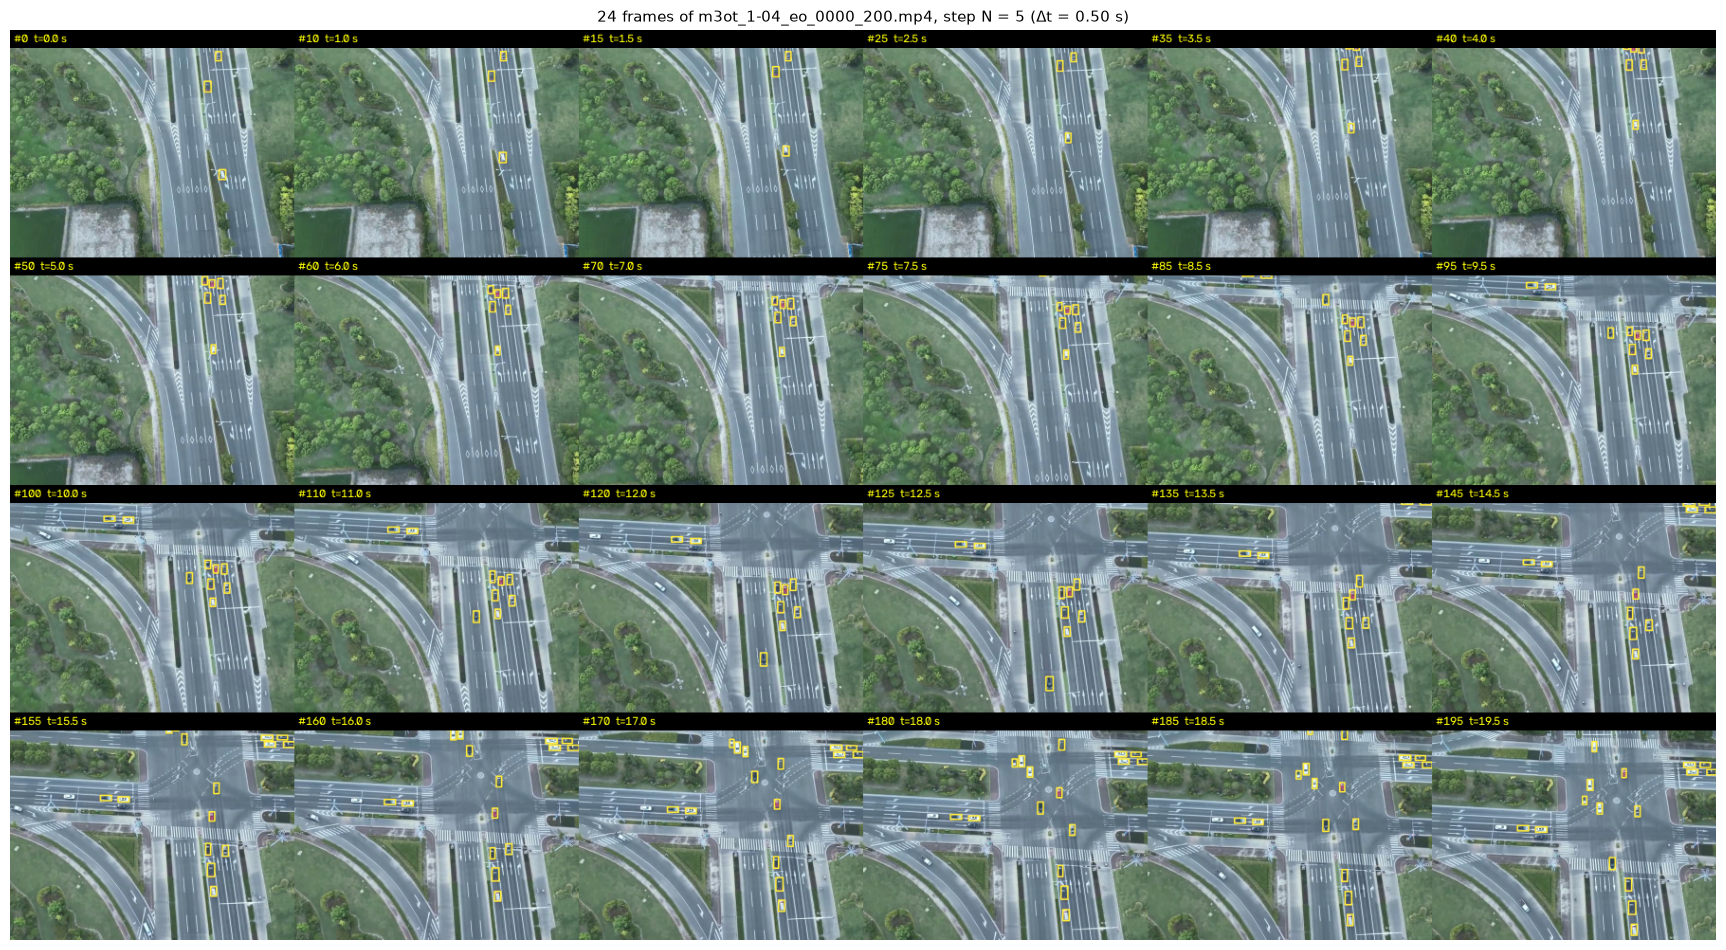

,time_s,mean,sharpness,vehicles,note
frame,,,,,
0,0.0,127.1,878,6,
10,1.0,127.2,728,6,
15,1.5,127.1,749,6,
25,2.5,127.4,687,6,
35,3.5,127.6,691,6,
40,4.0,128.1,696,6,
50,5.0,129.4,710,6,
60,6.0,130.4,758,6,
70,7.0,131.3,711,6,


In [8]:
#@title 1.4.3 Grid of frames for visual analysis [auto] { run: "auto", display-mode: "form" }
COLUMNS = 6 #@param {type:"slider", min:2, max:10, step:1}
FRAMES_IN_GRID = 24 #@param {type:"slider", min:4, max:60, step:2}
SHOW_TIME = True #@param {type:"boolean"}
SHOW_TRACKS = True #@param {type:"boolean"}

sel = np.unique(np.linspace(0, len(EXTRACTED_EO) - 1, min(FRAMES_IN_GRID, len(EXTRACTED_EO))).round().astype(int))
tab = None
if SHOW_TRACKS and VIDEO_EO_SOURCE.get("dataset") == "M3OT":
    tab = m3ot.tracks(VIDEO_EO_SOURCE["sequence"], "rgb")
grid_frames, labels, rows = [], [], []
for i in sel:
    k, t, fr = EXTRACTED_EO[i]
    n_obj = None
    if tab is not None:
        frame_id = VIDEO_EO_SOURCE["start_frame"] + k
        objs = m3ot.objects(tab, frame_id)
        if fr.shape[1] != 640:
            s = fr.shape[1] / 640
            objs = [dict(o, box=[v * s for v in o["box"]]) for o in objs]
        n_obj = len(objs)
        fr = aitbc.draw_boxes(fr, objs, color=(255, 235, 59), labels=False, thickness=2)
    grid_frames.append(fr)
    labels.append(f"#{k}  t={t:.1f} s")
    rows.append(dict(frame=k, time_s=round(t, 2), mean=round(float(aitbc.gray(EXTRACTED_EO[i][2]).mean()), 1),
                     sharpness=round(aitbc.sharpness(EXTRACTED_EO[i][2])), vehicles=n_obj))
sheet = aitbc.contact_sheet(grid_frames, cols=COLUMNS, width=1800, labels=labels if SHOW_TIME else None)
GRID_EO = sheet
fig, ax = plt.subplots(figsize=(18, 18 * sheet.shape[0] / sheet.shape[1]))
ax.imshow(sheet)
ax.set_title(f"{len(sel)} frames of {os.path.basename(VIDEO_EO)}, step N = {EXTRACTION_EO['N']} "
             f"(Δt = {EXTRACTION_EO['dt']:.2f} s)", fontsize=11)
ax.axis("off")
plt.tight_layout()
plt.show()
t_ = pd.DataFrame(rows)
med = t_.sharpness.median()
t_["note"] = np.where(t_.sharpness < 0.5 * med, "possibly blurred", "")
display(t_.set_index("frame").T if len(t_) <= 12 else t_.set_index("frame"))

## Task 1.4.4. Thermal video fragment by the same method

**Purpose.** To apply the method of tasks 1.4.1–1.4.3 to the thermal video of the same flight and to compare the two channels in time and in space.

For M3OT the visible and the thermal camera of one drone record the same scene, and the annotated vehicles have the same identifiers in both channels. The authors aligned the channels with an affine transform, but small residual errors remain. Two of them are measured here, with the annotations of the vehicles:

- the **spatial offset** $(\Delta x, \Delta y)$ — the median difference of the positions of the same vehicle in the thermal and in the visible frame;
- the **time offset** $\tau$ — the number of frames by which the thermal stream lags behind the visible one or leads it.

The time offset is the shift $\tau$ that minimises the spread of the offsets around their median. If the streams are synchronised, the spread is minimal at $\tau = 0$; with a time offset, a vehicle that moves with the speed $v$ px/frame is seen at different places in the two channels, and the spread is minimal at the true lag. Only moving vehicles carry information about the lag; in sequences with few moving vehicles the curve is flat and the estimate is uncertain. Multiplied by the speed of a vehicle (1–7 px per frame in M3OT), a lag of 3 frames (0.3 s) gives a position error of 3–20 px, comparable with the size of the vehicle (about 10 px). The time alignment of streams of different sensors is a task of the data-fusion modules of Topics 4–5.

**Parameters.**
- `SAMPLING_RATE_HZ` — sampling rate of the thermal frames (by default the same as in task 1.4.2);
- `COLUMNS`, `FRAMES_IN_GRID` — grid of the thermal frames;
- `SEARCH_LAG` — maximum lag searched, frames. The offsets are estimated from the annotations of the whole sequence (all frames, not only the fragment), because a short fragment contains too few moving vehicles.
- `OWN_VIDEO_IR` — path of an own thermal video on Google Drive; empty — the thermal video of the data set: the same flight for M3OT, otherwise a thermal video of HIT-UAV.

**Output.** The thermal video file in `data/video` and its properties; the grid of the thermal frames; a pair of frames visible / thermal of the same moment; for M3OT the curve of the spread of the offsets against the lag $\tau$, with the found time offset and spatial offset. For HIT-UAV thermal video in task 1.4.1 there is no visible pair: only the grid is produced. The thermal frames of M3OT are shown as recorded, in the black-hot palette (task 1.3.4): the bright vehicles on the dark road are cooler than the asphalt.

**Control question 9.** What error in metres does a time offset of 3 frames at 10 frames per second cause for a vehicle that drives at 15 m/s? How does it affect the fusion of detections of the two channels?

,task 1.4.1 (visible),task 1.4.4 (thermal)
video file,m3ot_1-04_eo_0000_200.mp4,m3ot_1-04_ir_0000_200.mp4
"frame rate, frames/s",10.00,10.00
step N (4),5,5
frames extracted,40,40


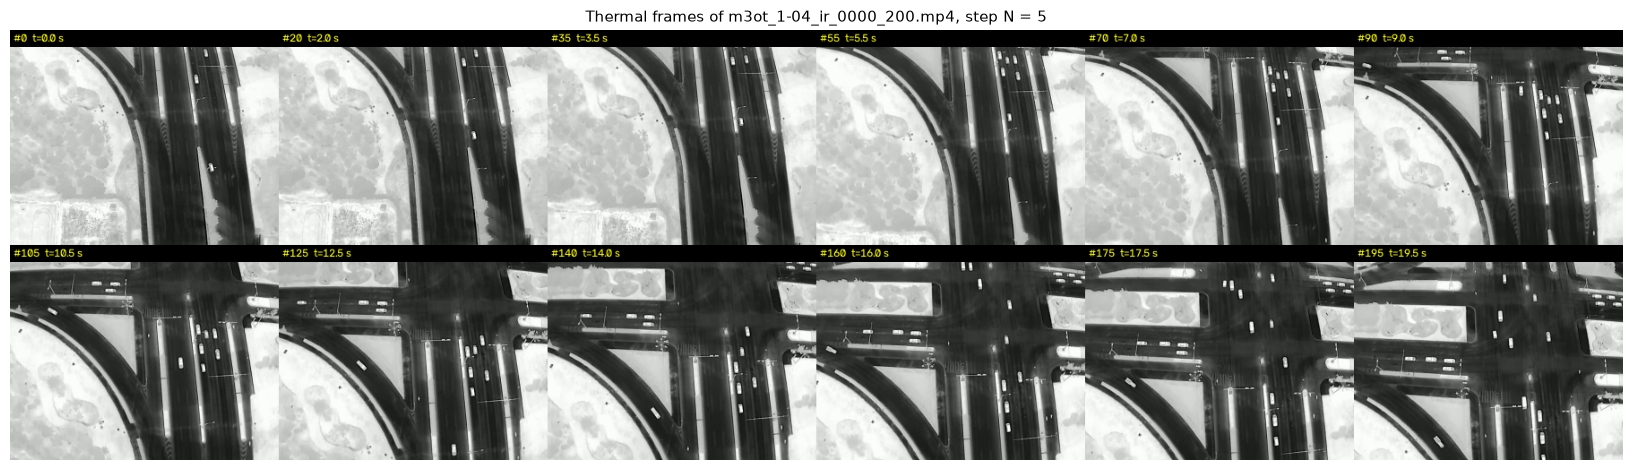

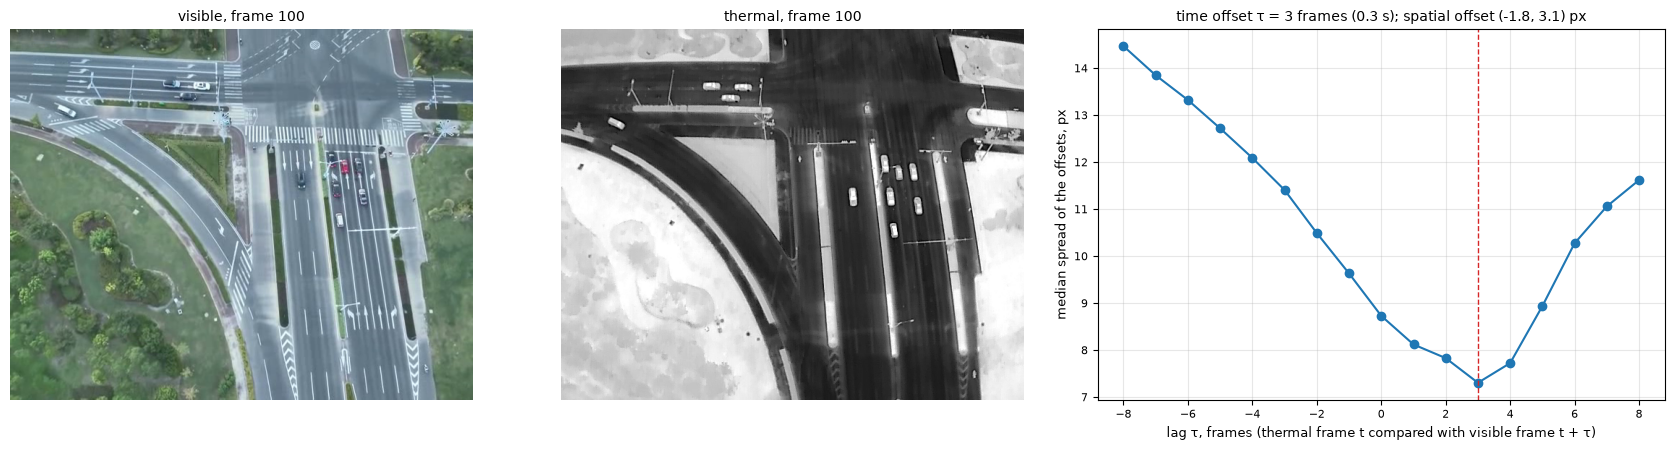

,Value
sequence,1-04
lag_frames,3
lag_s,0.3
offset_dx_px,-1.8
offset_dy_px,3.1
spread_px,7.3
spread_at_zero_px,8.73


In [9]:
#@title 1.4.4 Thermal video fragment and comparison of the channels [auto] { run: "auto", display-mode: "form" }
SAMPLING_RATE_HZ_IR = 2.0 #@param {type:"slider", min:0.2, max:30, step:0.2}
COLUMNS_IR = 6 #@param {type:"slider", min:2, max:10, step:1}
FRAMES_IN_GRID_IR = 12 #@param {type:"slider", min:4, max:48, step:2}
SEARCH_LAG = 8 #@param {type:"slider", min:1, max:15, step:1}
OWN_VIDEO_IR = "" #@param {type:"string"}

is_m3ot = VIDEO_EO_SOURCE.get("dataset") == "M3OT" and not OWN_VIDEO_IR
if OWN_VIDEO_IR:
    if IN_COLAB and OWN_VIDEO_IR.startswith("/content/drive") and not os.path.isdir("/content/drive/MyDrive"):
        from google.colab import drive
        drive.mount("/content/drive")
    if not os.path.isfile(OWN_VIDEO_IR):
        raise FileNotFoundError(f"{OWN_VIDEO_IR} not found: copy the thermal video to Google Drive or leave OWN_VIDEO_IR empty")
    VIDEO_IR = OWN_VIDEO_IR
    VIDEO_IR_SOURCE = dict(dataset="own video", path=OWN_VIDEO_IR, channel="thermal")
elif is_m3ot:
    seq_ = VIDEO_EO_SOURCE["sequence"]
    start, count = VIDEO_EO_SOURCE["start_frame"] - 1, VIDEO_EO_SOURCE["frames"]
    VIDEO_IR = os.path.join(PROJECT_ROOT, "data", "video", f"m3ot_{seq_}_ir_{start:04d}_{count}" + os.path.splitext(VIDEO_EO)[1])
    if not os.path.exists(VIDEO_IR):
        fr_ir = m3ot.frames(seq_, "ir", start=start, count=count)
        aitbc.write_video(VIDEO_IR, fr_ir, fps=m3ot.CAMERA["fps"], codec="mp4v" if VIDEO_IR.endswith(".mp4") else "MJPG")
        del fr_ir
    VIDEO_IR_SOURCE = dict(dataset="M3OT", sequence=seq_, channel="thermal", start_frame=start + 1, frames=count)
else:
    hv = VIDEO_EO_SOURCE.get("video", "70m-90_1.mov")
    VIDEO_IR = os.path.join(PROJECT_ROOT, "data", "video", "hituav_" + hv)
    if not os.path.exists(VIDEO_IR):
        shutil.copy2(hit.video(hv), VIDEO_IR)
    VIDEO_IR_SOURCE = dict(dataset="HIT-UAV", video=hv, channel="thermal")
info_ir = aitbc.video_info(VIDEO_IR)
N_ir = max(1, int(round(info_ir["fps"] / SAMPLING_RATE_HZ_IR)))                          # formula (4)
EXTRACTED_IR = [(k, t, fr) for k, t, fr in aitbc.iter_video(VIDEO_IR, every_n=N_ir, max_frames=300)]
EXTRACTION_IR = dict(video=VIDEO_IR, fps=info_ir["fps"], N=N_ir, fs=info_ir["fps"] / N_ir, dt=N_ir / info_ir["fps"], resize_width=0)
ch_141 = "visible" if VIDEO_EO_SOURCE.get("channel") != "thermal" else "thermal"
display(pd.DataFrame({f"task 1.4.1 ({ch_141})": [os.path.basename(VIDEO_EO), f"{aitbc.video_info(VIDEO_EO)['fps']:.2f}", EXTRACTION_EO["N"], len(EXTRACTED_EO)],
                      "task 1.4.4 (thermal)": [os.path.basename(VIDEO_IR), f"{info_ir['fps']:.2f}", N_ir, len(EXTRACTED_IR)]},
                     index=["video file", "frame rate, frames/s", "step N (4)", "frames extracted"]))
sel = np.unique(np.linspace(0, len(EXTRACTED_IR) - 1, min(FRAMES_IN_GRID_IR, len(EXTRACTED_IR))).round().astype(int))
GRID_IR = aitbc.contact_sheet([EXTRACTED_IR[i][2] for i in sel], cols=COLUMNS_IR, width=1800,
                              labels=[f"#{EXTRACTED_IR[i][0]}  t={EXTRACTED_IR[i][1]:.1f} s" for i in sel])
fig, ax = plt.subplots(figsize=(18, 18 * GRID_IR.shape[0] / GRID_IR.shape[1]))
ax.imshow(GRID_IR)
ax.set_title(f"Thermal frames of {os.path.basename(VIDEO_IR)}, step N = {N_ir}", fontsize=11)
ax.axis("off")
plt.tight_layout()
plt.show()

if is_m3ot:
    ta, tb = m3ot.tracks(seq_, "rgb"), m3ot.tracks(seq_, "ir")     # annotations of the whole sequence
    curve = []
    for tau in range(-SEARCH_LAG, SEARCH_LAG + 1):
        dx, dy = aitbc.track_offsets(ta, tb, lag=tau)
        if len(dx) < 20:
            continue
        cx, cy = np.median(dx), np.median(dy)
        curve.append((tau, float(np.median(np.hypot(dx - cx, dy - cy))), cx, cy, len(dx)))
    curve = pd.DataFrame(curve, columns=["tau", "spread", "dx", "dy", "pairs"])
    best = curve.loc[curve.spread.idxmin()]
    LAG_RESULT = dict(sequence=seq_, lag_frames=int(best.tau), lag_s=float(best.tau) / m3ot.CAMERA["fps"],
                      offset_dx_px=round(float(best.dx), 1), offset_dy_px=round(float(best.dy), 1),
                      spread_px=round(float(best.spread), 2), spread_at_zero_px=round(float(curve.set_index("tau").spread.get(0, np.nan)), 2))
    k_mid = len(EXTRACTED_EO) // 2
    k0 = EXTRACTED_EO[k_mid][0]
    eo_f = EXTRACTED_EO[k_mid][2]
    ir_f = m3ot.frames(seq_, "ir", start=start + k0, count=1)[0]
    if eo_f.shape[:2] != ir_f.shape[:2]:
        eo_f = cv2.resize(eo_f, (ir_f.shape[1], ir_f.shape[0]))
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 1.15]))
    ax[0].imshow(eo_f)
    ax[0].set_title(f"visible, frame {k0}", fontsize=10)
    ax[1].imshow(ir_f)
    ax[1].set_title(f"thermal, frame {k0}", fontsize=10)
    for a in ax[:2]:
        a.axis("off")
    ax[2].plot(curve.tau, curve.spread, "o-")
    ax[2].axvline(best.tau, color="C3", ls="--", lw=1)
    ax[2].set_xlabel("lag τ, frames (thermal frame t compared with visible frame t + τ)")
    ax[2].set_ylabel("median spread of the offsets, px")
    ax[2].set_title(f"time offset τ = {int(best.tau)} frames ({best.tau / m3ot.CAMERA['fps']:.1f} s); "
                    f"spatial offset ({best.dx:.1f}, {best.dy:.1f}) px", fontsize=10)
    ax[2].grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    display(pd.DataFrame({"Value": list(LAG_RESULT.values())}, index=list(LAG_RESULT.keys())))
else:
    LAG_RESULT = None
    print("This thermal video has no synchronised and annotated visible stream: the comparison of the channels is skipped.")

## Task 1.4.5. Saving of the frame sets in the folders of the project

**Purpose.** To save the extracted visible and thermal frames in `frames/visible` and `frames/thermal`, to record for every frame its origin (video, frame number, time) in an index table, and to save the grids of frames in `outputs/figures`.

**Parameters.**
- `FORMAT` — PNG (lossless) or JPEG (smaller files, compression artefacts); `JPEG_QUALITY` — quality of JPEG.
- `SET_NAME` — name of the set: a subfolder `frames/<channel>/<SET_NAME>` is created.
- `OVERWRITE` — replace an existing set with the same name.

**File names.** `<set>_<channel>_<frame number>.<format>`, for example `m3ot_1-04_eo_000040.png`. The index table `frames.csv` of every set has the columns: file, source video, frame number in the video, time, frame number in the data set, channel, width, height, file size.

**Output.** The number and volume of the saved files, the first lines of `frames.csv`, the record of the lesson in `project.json` and the tree of `frames/`.

**Control question 10.** Why is the frame number in the source video stored together with each saved frame? Which task of the following lessons needs it?

In [10]:
#@title 1.4.5 Saving of the frame sets { display-mode: "form" }
FORMAT = "png" #@param ["png", "jpg"]
JPEG_QUALITY = 95 #@param {type:"slider", min:50, max:100, step:5}
SET_NAME = "auto" #@param {type:"string"}
OVERWRITE = True #@param {type:"boolean"}


def save_set(extracted, extraction, source, channel):
    name = SET_NAME if SET_NAME and SET_NAME != "auto" else (
        f"m3ot_{source['sequence']}" if source.get("dataset") == "M3OT" else os.path.splitext(os.path.basename(extraction["video"]))[0])
    tag = "eo" if channel == "visible" else "ir"
    folder = os.path.join(PROJECT_ROOT, "frames", channel, name)
    if os.path.isdir(folder) and OVERWRITE:
        shutil.rmtree(folder)
    os.makedirs(folder, exist_ok=True)
    rows = []
    params = [cv2.IMWRITE_JPEG_QUALITY, int(JPEG_QUALITY)] if FORMAT == "jpg" else [cv2.IMWRITE_PNG_COMPRESSION, 3]
    for k, t, fr in extracted:
        fn = f"{name}_{tag}_{k:06d}.{FORMAT}"
        img = fr if fr.ndim == 2 else cv2.cvtColor(fr, cv2.COLOR_RGB2BGR)
        cv2.imwrite(os.path.join(folder, fn), img, params)
        rows.append(dict(file=fn, video=os.path.basename(extraction["video"]), frame_in_video=k, time_s=round(t, 3),
                         frame_in_dataset=(source.get("start_frame", 1) + k) if source.get("dataset") == "M3OT" else None,
                         channel=channel, width=fr.shape[1], height=fr.shape[0],
                         file_kb=round(os.path.getsize(os.path.join(folder, fn)) / 1024, 1)))
    index = pd.DataFrame(rows)
    index.to_csv(os.path.join(folder, "frames.csv"), index=False)
    return folder, index


results = {}
CH_EO = "visible" if VIDEO_EO_SOURCE.get("channel") != "thermal" else "thermal"     # channel of the video of task 1.4.1
for extracted, extraction, source, channel in ((EXTRACTED_EO, EXTRACTION_EO, VIDEO_EO_SOURCE, CH_EO),
                                               (EXTRACTED_IR, EXTRACTION_IR, VIDEO_IR_SOURCE, "thermal")):
    if extraction["video"] == VIDEO_EO and channel == "thermal" and VIDEO_IR == VIDEO_EO and "thermal" in results:
        continue
    folder, index = save_set(extracted, extraction, source, channel)
    results[channel if channel not in results else channel + "_2"] = (folder, index)
for name, grid in (("grid_visible" if CH_EO == "visible" else "grid_thermal_1_4_3", GRID_EO), ("grid_thermal", GRID_IR)):
    cv2.imwrite(os.path.join(PROJECT_ROOT, "outputs", "figures", f"lesson14_{name}.jpg"), cv2.cvtColor(grid, cv2.COLOR_RGB2BGR),
                [cv2.IMWRITE_JPEG_QUALITY, 90])
summary = []
for ch, (folder, index) in results.items():
    summary.append(dict(channel=ch, folder=os.path.relpath(folder, PROJECT_ROOT), files=len(index),
                        volume_MB=round(index.file_kb.sum() / 1024, 1), first=index.file.iloc[0], last=index.file.iloc[-1]))
display(pd.DataFrame(summary).set_index("channel"))
first_index = next(iter(results.values()))[1]
display(first_index.head(5))
meta = update_project_json("1.4", {"lesson_1_4": {
    "video_visible": (os.path.relpath(VIDEO_EO, PROJECT_ROOT) if VIDEO_EO.startswith(PROJECT_ROOT) else VIDEO_EO) if CH_EO == "visible" else None,
    "video_thermal": os.path.relpath(VIDEO_IR, PROJECT_ROOT) if VIDEO_IR.startswith(PROJECT_ROOT) else VIDEO_IR,
    "sampling": {"visible": {k: EXTRACTION_EO[k] for k in ("fps", "N", "fs", "dt")},
                 "thermal": {k: EXTRACTION_IR[k] for k in ("fps", "N", "fs", "dt")}},
    "sets": {ch: os.path.relpath(folder, PROJECT_ROOT) for ch, (folder, _) in results.items()},
    "channel_offset": LAG_RESULT, "source": [VIDEO_EO_SOURCE, VIDEO_IR_SOURCE]}})
print("project.json: lessons", meta["lessons"])
print_tree(os.path.join(PROJECT_ROOT, "frames"), max_files=3)

,folder,files,volume_MB,first,last
channel,,,,,
visible,frames\visible\m3ot_1-04,40,15.5,m3ot_1-04_eo_000000.png,m3ot_1-04_eo_000195.png
thermal,frames\thermal\m3ot_1-04,40,8.9,m3ot_1-04_ir_000000.png,m3ot_1-04_ir_000195.png


,file,video,frame_in_video,time_s,frame_in_dataset,channel,width,height,file_kb
0,m3ot_1-04_eo_000000.png,m3ot_1-04_eo_0000_200.mp4,0,0.0,1,visible,640,512,351.9
1,m3ot_1-04_eo_000005.png,m3ot_1-04_eo_0000_200.mp4,5,0.5,6,visible,640,512,388.9
2,m3ot_1-04_eo_000010.png,m3ot_1-04_eo_0000_200.mp4,10,1.0,11,visible,640,512,396.0
3,m3ot_1-04_eo_000015.png,m3ot_1-04_eo_0000_200.mp4,15,1.5,16,visible,640,512,395.4
4,m3ot_1-04_eo_000020.png,m3ot_1-04_eo_0000_200.mp4,20,2.0,21,visible,640,512,401.9


project.json: lessons ['1.3', '1.4']
├── thermal/
│   ├── m3ot_1-02/
│   │   ├── frames.csv  (0 KB)
│   │   └── m3ot_1-02_ir_000000.png  (167 KB)
│   ├── m3ot_1-04/
│   │   ├── frames.csv  (3 KB)
│   │   ├── m3ot_1-04_ir_000000.png  (196 KB)
│   │   ├── m3ot_1-04_ir_000005.png  (224 KB)
│   │   └── … 38 more files
│   ├── own_test/
│   │   ├── frames.csv  (20 KB)
│   │   ├── own_test_ir_000000.png  (185 KB)
│   │   ├── own_test_ir_000004.png  (205 KB)
│   │   └── … 260 more files
│   ├── test_end/
│   │   ├── frames.csv  (0 KB)
│   │   └── test_end_ir_000000.png  (208 KB)
│   └── test_hit/
│       ├── frames.csv  (5 KB)
│       ├── test_hit_ir_000000.jpg  (19 KB)
│       ├── test_hit_ir_000004.jpg  (20 KB)
│       └── … 58 more files
└── visible/
    ├── goose_2022-09-21_garching_uebungsplatz_2/
    │   ├── frames.csv  (3 KB)
    │   ├── goose_2022-09-21_garching_uebungsplatz_2_eo_000000.png  (2706 KB)
    │   ├── goose_2022-09-21_garching_uebungsplatz_2_eo_000001.png  (2528 KB)
    │ 

## Task 1.4.6. Additional task: video stream of a ground robotic platform

**Purpose.** To apply the same method to the front camera of a ground vehicle (GOOSE data set). The camera records a sequence with time stamps of a recording session (the data set stores selected frames of the sessions). Compared with a UAV, the view is oblique and low, the scene changes quickly near the vehicle and slowly far away, and the traversable part of the frame (road, track, grass) is the main information for the platform.

**Parameters.** `SESSION` — recording session of GOOSE; `N_FRAMES` — number of frames; `SHOW_TRAVERSABLE` — traversable (green), conditionally traversable (yellow) and obstacle (red) areas from the pixel labels; `SAVE` — save the frames in `frames/visible/goose_<session>` with an index table.

**Output.** The grid of the frames with their times from the time stamps, the interval between successive frames, and the share of the traversable area of every frame.

**Control question 11.** Why do the intervals between the frames of the GOOSE sessions differ, while the frames of a video file have a constant interval? What does this mean for a tracking algorithm?

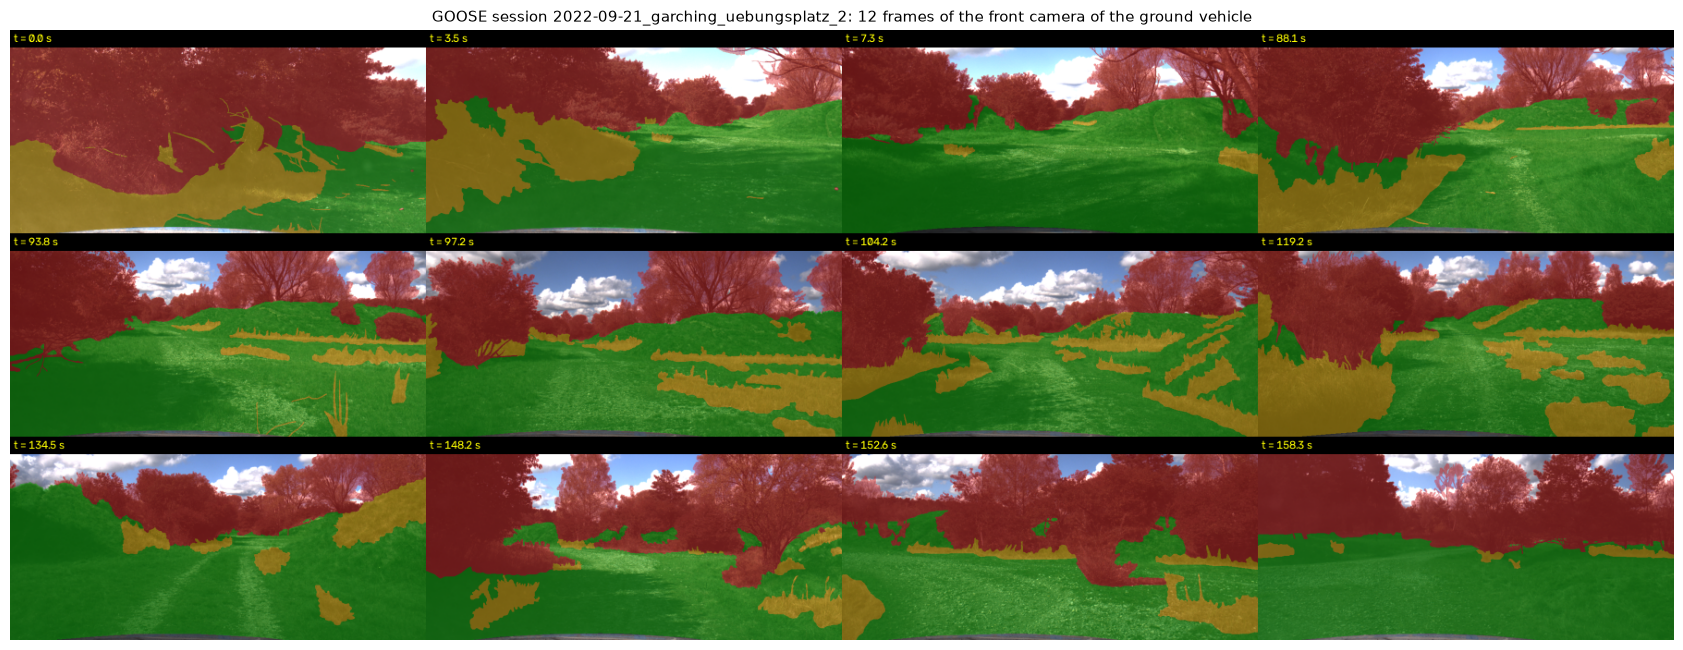

,0,1,2,3,4,5,6,7,8,9,10,11
"time, s",0.00,3.52,7.25,88.14,93.84,97.15,104.19,119.21,134.54,148.21,152.56,158.26
"interval to the previous frame, s",NaN,3.52,3.73,80.89,5.70,3.31,7.04,15.02,15.33,13.67,4.35,5.70
traversable share,0.16,0.44,0.61,0.40,0.56,0.49,0.47,0.36,0.65,0.39,0.42,0.51


In [11]:
#@title 1.4.6 Video stream of a ground robotic platform (GOOSE) { display-mode: "form" }
SESSION = "2022-09-21_garching_uebungsplatz_2" #@param ["2022-07-22_flight", "2022-08-30_siegertsbrunn_feldwege", "2022-09-21_garching_uebungsplatz_2", "2022-12-07_aying_hills", "2023-03-03_garching_2", "2023-05-17_neubiberg_sunny"]
N_FRAMES = 12 #@param {type:"slider", min:4, max:24, step:2}
SHOW_TRAVERSABLE = True #@param {type:"boolean"}
SAVE = False #@param {type:"boolean"}

frs = [n for n in goose.frames() if n.split("/")[2] == SESSION]
frs = sorted(frs, key=lambda n: int(n.split("__")[1].split("_")[0]))
first = len(frs) // 3
picked = frs[first:first + N_FRAMES]
goose.prefetch(picked)
stamps = np.array([int(n.split("__")[1].split("_")[1]) for n in picked]) / 1e9
imgs, shares = [], []
for lm in picked:
    img, lab = goose.load(lm, scale=0.5)
    tv = goose.traversability(lab)
    valid = tv > 0
    shares.append((tv == 1).sum() / max(valid.sum(), 1))
    if SHOW_TRAVERSABLE:
        col = np.zeros_like(img)
        col[tv == 1], col[tv == 2], col[tv == 3] = (0, 200, 0), (255, 200, 0), (230, 30, 30)
        img = aitbc.overlay(img, col, 0.4, tv > 0)
    imgs.append(img)
t_rel = stamps - stamps[0]
sheet = aitbc.contact_sheet(imgs, cols=4, width=1800, labels=[f"t = {t:.1f} s" for t in t_rel])
fig, ax = plt.subplots(figsize=(18, 18 * sheet.shape[0] / sheet.shape[1]))
ax.imshow(sheet)
ax.set_title(f"GOOSE session {SESSION}: {len(picked)} frames of the front camera of the ground vehicle", fontsize=11)
ax.axis("off")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"time, s": np.round(t_rel, 2), "interval to the previous frame, s": np.r_[np.nan, np.round(np.diff(t_rel), 2)],
                      "traversable share": np.round(shares, 2)}).T)
if SAVE:
    folder = os.path.join(PROJECT_ROOT, "frames", "visible", "goose_" + SESSION)
    os.makedirs(folder, exist_ok=True)
    rows = []
    for k, (lm, t) in enumerate(zip(picked, t_rel)):
        img, _ = goose.load(lm, scale=1.0)
        fn = f"goose_{SESSION}_eo_{k:06d}.png"
        cv2.imwrite(os.path.join(folder, fn), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
        rows.append(dict(file=fn, source=lm.split("/")[-1].replace("_labelids.png", ""), time_s=round(float(t), 3)))
    pd.DataFrame(rows).to_csv(os.path.join(folder, "frames.csv"), index=False)
    print(f"Saved {len(rows)} frames in {os.path.relpath(folder, PROJECT_ROOT)}")

### Report of Lesson 1.4

Double-click this cell and write the answers.

1. Video fragment of task 1.4.1: source, frame rate, duration, data rate (3), compression ratio; answer to control question 6:
2. Chosen sampling rate, step $N$, actual rate and $\Delta t$ (4); median displacement between extracted frames; answer to control question 7:
3. Observations in the grid of frames; answer to control question 8:
4. Time offset and spatial offset between the thermal and the visible channel (task 1.4.4); answer to control question 9:
5. Folders and number of the saved frames; answer to control question 10:
6. (Additional) Answer to control question 11:

---
## Final self-check of Topic 1

1. Which properties of a video file are read with `cv2.VideoCapture.get`, and how is the duration computed?
2. Why is a video decoded frame by frame with a generator instead of loading all frames into a list?
3. Calculate the number of frames of a 5-minute thermal video at 9 frames per second decomposed with $f_s$ = 1.5 Hz. *(N = 6, f_s' = 1.5 Hz, 450 frames.)*
4. Why are the frames of a visible and a thermal camera of the same UAV not aligned automatically, and which two kinds of misalignment were measured in task 1.4.4?
5. Describe the structure of the course project and the purpose of every folder.

## Data sources and licences

The course library reads the files directly from the repositories of the authors; the data are not redistributed with the notebook. When images or results are published, the data sets are cited.

1. **M3OT.** Nie Z., Xue L., Fang Z., Ren J., Wei Y., Zheng J. M3OT: A Multi-Drone Multi-Modality dataset for Multi-Object Tracking. *Scientific Data*, 12, 1927 (2025). https://doi.org/10.1038/s41597-025-06204-0 · Data: https://doi.org/10.6084/m9.figshare.28308887 · Licence CC BY 4.0.
2. **HIT-UAV.** Suo J., Wang T., Zhang X., Chen H., Zhou W., Shi W. HIT-UAV: A high-altitude infrared thermal dataset for Unmanned Aerial Vehicle-based object detection. *Scientific Data*, 10, 227 (2023). https://doi.org/10.1038/s41597-023-02066-6 · Data: https://github.com/suojiashun/HIT-UAV-Infrared-Thermal-Dataset · Licence CC BY 4.0.
3. **Kust4K.** Ouyang J., Wang Q., Shang Y., Jin P., Zhong H., Zhou L., Shen T. An RGB-TIR dataset from UAV platform for robust urban traffic scenes semantic segmentation. *Scientific Data*, 12, 1701 (2025). https://doi.org/10.1038/s41597-025-05994-7 · Data: https://doi.org/10.6084/m9.figshare.29476610 · Licence CC BY 4.0.
4. **VisDrone.** Zhu P., Wen L., Du D., Bian X., Fan H., Hu Q., Ling H. Detection and tracking meet drones challenge. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 44(11), 7380–7399 (2022). Data: https://github.com/VisDrone/VisDrone-Dataset · Terms of use: see the data set page.
5. **GOOSE.** Mortimer P., Hagmanns R., Granero M., Luettel T., Petereit J., Wuensche H.-J. The GOOSE dataset for perception in unstructured environments. *IEEE ICRA*, 2024. https://arxiv.org/abs/2310.16788 · Data: https://goose-dataset.de · Licence CC BY-SA 4.0.

**Next notebook.** Notebook 03 — Topic 2, Lessons 2.1 and 2.2: the digital image and the video stream of electro-optical surveillance devices; stages of preprocessing of video frames.